In [1]:
import hashlib
import os
import re
import textwrap
import time
from itertools import combinations

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.utils import to_categorical

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, auc, classification_report,
                             confusion_matrix, roc_curve, silhouette_score)
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

try:
    from catboost import CatBoostClassifier
    CATBOOST_AVAILABLE = True
except ImportError:
    CATBOOST_AVAILABLE = False
    print("CatBoost not available. Skipping it.")

2026-11-14 07:26:23.002378: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1794641183.187407      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1794641183.242483      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1794641183.716586      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794641183.716635      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1794641183.716638      57 computation_placer.cc:177] computation placer alr

In [2]:
input_shape = (224, 224, 3)
num_classes = 5

base_dir = "/kaggle/input/datasets/prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed"
classes = ["im_Dyskeratotic", "im_Metaplastic", "im_Koilocytotic", "im_Parabasal", "im_Superficial-Intermediate"]
class_names = ['Dyskeratotic', 'Metaplastic', 'Koilocytotic', 'Parabasal', 'Superficial-Intermediate']

cropped_dirs = {cls: os.path.join(base_dir, cls, cls, "CROPPED") for cls in classes}

In [3]:
def load_images_from_directory(directory, target_size=(224, 224)):
    images, filenames = [], []
    for filename in sorted(os.listdir(directory)):
        img = cv2.imread(os.path.join(directory, filename))
        if img is not None:
            img = cv2.resize(img, target_size)
            images.append(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            filenames.append(filename)
    return np.array(images), filenames


cropped_images, cropped_labels, cropped_groups = {}, {}, {}
for cls, dir_path in cropped_dirs.items():
    images, filenames = load_images_from_directory(dir_path)
    cropped_images[cls] = images
    cropped_labels[cls] = np.full(len(images), cls)
    cropped_groups[cls] = np.array([f"{cls}_{re.split(r'[_.]', fn)[0]}" for fn in filenames])

X_cropped = np.concatenate(list(cropped_images.values()))
y_cropped = np.concatenate(list(cropped_labels.values()))
groups = np.concatenate(list(cropped_groups.values()))

label_to_index = {cls: idx for idx, cls in enumerate(cropped_dirs.keys())}
y_cropped = np.array([label_to_index[label] for label in y_cropped])
y_cropped = to_categorical(y_cropped, num_classes=num_classes)

In [4]:
def group_split_per_class(y_int, groups, fractions=(0.80, 0.15, 0.05)):
    rng = np.random.RandomState(42)
    split_of_group = {}
    for c in np.unique(y_int):
        idx = np.where(y_int == c)[0]
        ugroups = np.unique(groups[idx])
        rng.shuffle(ugroups)
        sizes = {g: np.sum(groups[idx] == g) for g in ugroups}
        targets = [f * len(idx) for f in fractions]
        filled = [0, 0, 0]
        for g in ugroups:
            s = int(np.argmax([(targets[k] - filled[k]) / targets[k] for k in range(3)]))
            split_of_group[g] = s
            filled[s] += sizes[g]
    return np.array([split_of_group[g] for g in groups])


split_id = group_split_per_class(y_cropped.argmax(axis=1), groups)

X_train, y_train = X_cropped[split_id == 0], y_cropped[split_id == 0]
X_val,   y_val   = X_cropped[split_id == 1], y_cropped[split_id == 1]
X_test,  y_test  = X_cropped[split_id == 2], y_cropped[split_id == 2]

y_val_classes = np.argmax(y_val, axis=1)
y_test_classes = np.argmax(y_test, axis=1)
groups_val = groups[split_id == 1]   # needed later for group-aware cross-validation on the validation set

print(f"Train: {len(X_train)} imgs / {len(set(groups[split_id == 0]))} groups")
print(f"Val  : {len(X_val)} imgs / {len(set(groups_val))} groups")
print(f"Test : {len(X_test)} imgs / {len(set(groups[split_id == 2]))} groups")
print("Example group ids:", list(groups[:3]), "...")

# sanity checks: grouping must really group (otherwise the regex failed and every image is its own group)
print(f"Mean images per group: {len(groups) / len(set(groups)):.2f}")
assert len(set(groups)) < 0.9 * len(groups), "Group extraction looks wrong: almost every image is its own group"
for k, nm in enumerate(["Train", "Val", "Test"]):
    print(nm, "class counts:", np.bincount(y_cropped[split_id == k].argmax(axis=1), minlength=num_classes))

Train: 3192 imgs / 758 groups
Val  : 630 imgs / 148 groups
Test : 227 imgs / 60 groups
Example group ids: [np.str_('im_Dyskeratotic_001'), np.str_('im_Dyskeratotic_001'), np.str_('im_Dyskeratotic_001')] ...
Mean images per group: 4.19
Train class counts: [637 627 643 624 661]
Val class counts: [131 125 123 124 127]
Test class counts: [45 41 59 39 43]


In [5]:
g_train, g_val, g_test = (set(groups[split_id == k]) for k in range(3))
assert not (g_train & g_val), "DATA LEAK: groups shared between train and val"
assert not (g_train & g_test), "DATA LEAK: groups shared between train and test"
assert not (g_val & g_test), "DATA LEAK: groups shared between val and test"

def image_hashes(X):
    return {hashlib.md5(x.tobytes()).hexdigest() for x in X}

h_train, h_val, h_test = image_hashes(X_train), image_hashes(X_val), image_hashes(X_test)
assert not (h_train & h_val), "DATA LEAK: identical images shared between train and val"
assert not (h_train & h_test), "DATA LEAK: identical images shared between train and test"
assert not (h_val & h_test), "DATA LEAK: identical images shared between val and test"

print("No group or exact-duplicate overlap between train / val / test.")

No group or exact-duplicate overlap between train / val / test.


In [6]:
class ClusterAttentionBlock(tf.keras.layers.Layer):
    def __init__(self, num_clusters, **kwargs):
        super(ClusterAttentionBlock, self).__init__(**kwargs)
        self.num_clusters = num_clusters
        self.conv1x1 = tf.keras.layers.Conv2D(1, kernel_size=1, use_bias=False)
        self.dense = tf.keras.layers.Dense(num_clusters, activation='sigmoid')

    def call(self, feature_maps):
        batch_size = tf.shape(feature_maps)[0]
        h, w, num_channels = feature_maps.shape[1:]
        maps_per_cluster = num_channels // self.num_clusters

        reshaped = tf.reshape(feature_maps, (batch_size, h, w, self.num_clusters, maps_per_cluster))
        temp_batch = batch_size * self.num_clusters
        conv_input = tf.reshape(reshaped, (temp_batch, h, w, maps_per_cluster))

        fused = self.conv1x1(conv_input)
        fused = tf.reshape(fused, (batch_size, h, w, self.num_clusters))

        squeezed = tf.reduce_mean(fused, axis=[1, 2])
        weights = self.dense(squeezed)
        weighted = fused * tf.reshape(weights, (batch_size, 1, 1, self.num_clusters))

        final_map = tf.reduce_max(weighted, axis=-1, keepdims=True)
        vector_output = tf.reduce_mean(weighted, axis=[1, 2])

        return final_map, vector_output

    def get_config(self):
        config = super().get_config()
        config.update({"num_clusters": self.num_clusters})
        return config

    def compute_output_spec(self, input_spec):
        batch_size, h, w, num_channels = input_spec.shape
        if num_channels % self.num_clusters != 0:
            raise ValueError(f"Number of channels ({num_channels}) must be divisible by num_clusters ({self.num_clusters})")

        final_map_spec = tf.keras.KerasTensor(shape=(batch_size, h, w, 1), dtype=tf.float32)
        vector_output_spec = tf.keras.KerasTensor(shape=(batch_size, self.num_clusters), dtype=tf.float32)
        return final_map_spec, vector_output_spec


custom_objects = {'ASCFBlock': ClusterAttentionBlock, 'ClusterAttentionBlock': ClusterAttentionBlock}

### Model paths

| Version | Backbone | Version | Backbone (pretrained) |
|---|---|---|---|
| v15 | VGG16 | v8 | VGG16 |
| v2 | VGG19 | v9 | VGG19 |
| v3 | ResNet50 | v10 | ResNet50 |
| v4 | MobileNet | v11 | MobileNet |
| v5 | DenseNet121 | v12 | DenseNet121 |
| v6 | Xception | v13 | Xception |
| v7 | Inception | v14 | Inception |

In [7]:
models_dir = "/kaggle/input/models/anzumshreya/cer-vical/tensorflow2/vgg16"

versions = {"VGG16": 15, "VGG19": 2, "ResNet50": 3, "MobileNet": 4,
            "DenseNet": 5, "Xception": 6, "Inception": 7}

reported_accuracy = {
    "GAP": {"VGG16": 0.9383, "VGG19": 0.9339, "ResNet50": 0.9339, "MobileNet": 0.9031,
            "DenseNet": 0.9383, "Xception": 0.9163, "Inception": 0.9163},
    "CA": {"VGG16": 0.9604, "VGG19": 0.9559, "ResNet50": 0.9692, "MobileNet": 0.9251,
           "DenseNet": 0.9515, "Xception": 0.9427, "Inception": 0.9427},
    "pretrained": {"VGG16": 0.9251, "VGG19": 0.9251, "ResNet50": 0.9427, "MobileNet": 0.9031,
                   "DenseNet": 0.9339, "Xception": 0.9163, "Inception": 0.9207},
}

model_info = {}
for variant in ["GAP", "CA", "pretrained"]:
    for backbone, v in versions.items():
        if variant == "GAP":
            path = f"{models_dir}/{v}/cervical_cancer_model_gap.h5"
        elif variant == "CA":
            path = f"{models_dir}/{v}/cervical_cancer_model.h5"
        else:
            if backbone == "VGG16":
                path = f"{models_dir}/{8}/cervical_cancer_model.h5"
            else:
                path = f"{models_dir}/{v + 7}/cervical_cancer_model.h5"
        model_info[f"{backbone}_{variant}"] = {"path": path, "accuracy": reported_accuracy[variant][backbone]}

ca_models = [name for name in model_info if name.endswith("_CA")]


def load_cervical_model(name):
    return load_model(model_info[name]["path"], custom_objects=custom_objects)

In [8]:
val_predictions, test_predictions, test_time_per_image = {}, {}, {}
mismatched = []

for name, info in model_info.items():
    print(f"Loading {name} ...")
    K.clear_session()
    model = load_cervical_model(name)

    val_predictions[name] = model.predict(X_val, verbose=0)

    model.predict(X_test[:32], verbose=0) 
    start = time.time()
    test_predictions[name] = model.predict(X_test, verbose=0)
    test_time_per_image[name] = (time.time() - start) / len(X_test)

    val_acc = accuracy_score(y_val_classes, np.argmax(val_predictions[name], axis=1))
    test_acc = accuracy_score(y_test_classes, np.argmax(test_predictions[name], axis=1))
    print(f"{name} Val Accuracy: {val_acc:.6f} | Test Accuracy: {test_acc:.6f} "
          f"(Reported: {info['accuracy']:.6f}) | time per image: {test_time_per_image[name]:.6f}s")

    if abs(test_acc - info['accuracy']) > 0.001:
        print(f"  WARNING: {name} does not reproduce its recorded accuracy, "
              f"the split may differ from the one used for training")
        mismatched.append(name)
    del model

assert not mismatched, f"Split does not reproduce the training split for: {mismatched}"


Loading VGG16_GAP ...


I0000 00:00:1794642100.819201      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1794642100.825380      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
I0000 00:00:1794642106.730648     144 service.cc:152] XLA service 0x7831300501a0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1794642106.730687     144 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1794642106.730690     144 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1794642107.052600     144 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1794642122.013806     144 device_compiler.h:188] Compiled clust

VGG16_GAP Val Accuracy: 0.952381 | Test Accuracy: 0.938326 (Reported: 0.938300) | time per image: 0.020597s
Loading VGG19_GAP ...


VGG19_GAP Val Accuracy: 0.928571 | Test Accuracy: 0.933921 (Reported: 0.933900) | time per image: 0.010014s
Loading ResNet50_GAP ...


ResNet50_GAP Val Accuracy: 0.944444 | Test Accuracy: 0.933921 (Reported: 0.933900) | time per image: 0.020348s
Loading MobileNet_GAP ...


2026-11-14 07:43:12.465557: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-14 07:43:12.603299: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-14 07:43:22.497397: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-14 07:43:22.634969: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-14 07:43:31.140454: E external/local_xla/xla/stream_

... (15 outputs left out)

MobileNet_pretrained Val Accuracy: 0.933333 | Test Accuracy: 0.903084 (Reported: 0.903100) | time per image: 0.009999s
Loading DenseNet_pretrained ...


DenseNet_pretrained Val Accuracy: 0.946032 | Test Accuracy: 0.933921 (Reported: 0.933900) | time per image: 0.037784s
Loading Xception_pretrained ...


Xception_pretrained Val Accuracy: 0.941270 | Test Accuracy: 0.916300 (Reported: 0.916300) | time per image: 0.017958s
Loading Inception_pretrained ...


Inception_pretrained Val Accuracy: 0.936508 | Test Accuracy: 0.920705 (Reported: 0.920700) | time per image: 0.017756s


## Individual model performance

In [9]:
rows = []
for name in model_info:
    y_pred = np.argmax(test_predictions[name], axis=1)
    report = classification_report(y_test_classes, y_pred, target_names=class_names,
                                   output_dict=True, zero_division=0)
    rows.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test_classes, y_pred),
        'Precision': report['macro avg']['precision'],
        'Recall': report['macro avg']['recall'],
        'F1-Score': report['macro avg']['f1-score'],
        'Time/Image (s)': test_time_per_image[name],
    })

df_metrics = pd.DataFrame(rows).set_index('Model')

display(df_metrics.style
        .format("{:.5f}")
        .format("{:.6f}", subset=['Time/Image (s)'])
        .set_properties(**{'text-align': 'center'}))

try:
    print("\nMarkdown version for copying:")
    print(df_metrics.to_markdown(floatfmt=".5f"))
except ImportError:
    pass  # tabulate not installed

,Accuracy,Precision,Recall,F1-Score,Time/Image (s)
Model,,,,,
VGG16_GAP,0.93833,0.94604,0.94218,0.94253,0.020597
VGG19_GAP,0.93392,0.94768,0.93346,0.93735,0.010014
ResNet50_GAP,0.93392,0.94655,0.93284,0.93663,0.020348
MobileNet_GAP,0.90308,0.90790,0.90992,0.90759,0.036664
DenseNet_GAP,0.93833,0.94187,0.94429,0.94191,0.047756
Xception_GAP,0.91630,0.92581,0.92139,0.92173,0.041727
Inception_GAP,0.91630,0.92943,0.91779,0.91906,0.033031
VGG16_CA,0.96035,0.95871,0.96397,0.96060,0.010766
VGG19_CA,0.95595,0.95673,0.95909,0.95749,0.012159



Markdown version for copying:
| Model                |   Accuracy |   Precision |   Recall |   F1-Score |   Time/Image (s) |
|:---------------------|-----------:|------------:|---------:|-----------:|-----------------:|
| VGG16_GAP            |    0.93833 |     0.94604 |  0.94218 |    0.94253 |          0.02060 |
| VGG19_GAP            |    0.93392 |     0.94768 |  0.93346 |    0.93735 |          0.01001 |
| ResNet50_GAP         |    0.93392 |     0.94655 |  0.93284 |    0.93663 |          0.02035 |
| MobileNet_GAP        |    0.90308 |     0.90790 |  0.90992 |    0.90759 |          0.03666 |
| DenseNet_GAP         |    0.93833 |     0.94187 |  0.94429 |    0.94191 |          0.04776 |
| Xception_GAP         |    0.91630 |     0.92581 |  0.92139 |    0.92173 |          0.04173 |
| Inception_GAP        |    0.91630 |     0.92943 |  0.91779 |    0.91906 |          0.03303 |
| VGG16_CA             |    0.96035 |     0.95871 |  0.96397 |    0.96060 |          0.01077 |
| VGG19_CA         

## Meta-classifiers (CA models)

In [10]:
def wrap_label(text, width=14):
    return textwrap.fill(text, width=width, break_on_hyphens=True)


wrapped_class_names = [wrap_label(n) for n in class_names]


def plot_confusion_matrix(y_true, y_pred, title, save_name):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(9, 7))
    ax = sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                     xticklabels=wrapped_class_names, yticklabels=wrapped_class_names)
    ax.set_xticklabels(wrapped_class_names, rotation=0, ha='center', fontsize=10)  
    ax.set_yticklabels(wrapped_class_names, rotation=0, va='center', fontsize=10)
    plt.title(f'Confusion Matrix\n{title}', fontsize=14)
    plt.xlabel('Predicted', fontsize=12)
    plt.ylabel('True', fontsize=12)
    plt.tight_layout()
    plt.savefig(f'{save_name}_cm.png', dpi=150)
    plt.show()


def plot_roc_curves(y_true_onehot, probs, title, save_name):
    plt.figure(figsize=(10, 8))
    for i in range(num_classes):
        fpr, tpr, _ = roc_curve(y_true_onehot[:, i], probs[:, i])
        plt.plot(fpr, tpr, label=f'{class_names[i]} (AUC = {auc(fpr, tpr):.4f})')
    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate', fontsize=12)
    plt.title(f'ROC Curve\n{title}', fontsize=14)
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.savefig(f'{save_name}_roc.png')
    plt.show()

In [11]:
def get_meta_classifiers():
    meta_classifiers = {
        "KNN": KNeighborsClassifier(n_neighbors=5),
        "MLP": MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=1000, random_state=42),
        "RandomForest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    }
    if CATBOOST_AVAILABLE:
        meta_classifiers["CatBoost"] = CatBoostClassifier(iterations=300, verbose=0, random_state=42)
    return meta_classifiers


def run_meta_classifiers(base_name, show_plots=False):
    val_preds = val_predictions[base_name]
    test_preds = test_predictions[base_name]

    base_acc = accuracy_score(y_test_classes, np.argmax(test_preds, axis=1))
    print("=" * 70)
    print(f"{base_name} + Meta-Classifiers (base accuracy on test: {base_acc:.6f})")
    print("=" * 70)

    for meta_name, meta_model in get_meta_classifiers().items():
        print(f"\n--- {base_name} + {meta_name} ---")

        start = time.time()
        meta_model.fit(val_preds, y_val_classes)
        train_time = time.time() - start

        start = time.time()
        y_pred = np.asarray(meta_model.predict(test_preds)).ravel().astype(int)  
        probs = meta_model.predict_proba(test_preds)
        inference_time = time.time() - start

        print(f"Test Accuracy       : {accuracy_score(y_test_classes, y_pred):.6f}")
        print(f"Meta training time  : {train_time:.6f} s")
        print(f"Test time per image : {inference_time / len(X_test):.6f} s")

        print("\nClassification Report:")
        print(classification_report(y_test_classes, y_pred, target_names=class_names, digits=6))

        if show_plots:
            save_name = f'{base_name}_{meta_name}'
            plot_confusion_matrix(y_test_classes, y_pred, f'{base_name} + {meta_name}', save_name)
            plot_roc_curves(y_test, probs, f'{base_name} + {meta_name}', save_name)

### ResNet50_CA

In [12]:
run_meta_classifiers("ResNet50_CA")

ResNet50_CA + Meta-Classifiers (base accuracy on test: 0.969163)

--- ResNet50_CA + KNN ---
Test Accuracy       : 0.964758
Meta training time  : 0.015410 s
Test time per image : 0.000024 s

Classification Report:
                          precision    recall  f1-score   support

            Dyskeratotic   0.977273  0.955556  0.966292        45
             Metaplastic   0.950000  0.926829  0.938272        41
            Koilocytotic   0.933333  0.949153  0.941176        59
               Parabasal   1.000000  1.000000  1.000000        39
Superficial-Intermediate   0.977273  1.000000  0.988506        43

                accuracy                       0.964758       227
               macro avg   0.967576  0.966307  0.966849       227
            weighted avg   0.964831  0.964758  0.964702       227


--- ResNet50_CA + MLP ---
Test Accuracy       : 0.969163
Meta training time  : 0.794543 s
Test time per image : 0.000006 s

Classification Report:
                          precision    rec

### VGG16_CA

VGG16_CA + Meta-Classifiers (base accuracy on test: 0.960352)

--- VGG16_CA + KNN ---
Test Accuracy       : 0.942731
Meta training time  : 0.002702 s
Test time per image : 0.000021 s

Classification Report:
                          precision    recall  f1-score   support

            Dyskeratotic   1.000000  0.955556  0.977273        45
             Metaplastic   0.918919  0.829268  0.871795        41
            Koilocytotic   0.887097  0.932203  0.909091        59
               Parabasal   0.928571  1.000000  0.962963        39
Superficial-Intermediate   1.000000  1.000000  1.000000        43

                accuracy                       0.942731       227
               macro avg   0.946917  0.943405  0.944224       227
            weighted avg   0.943739  0.942731  0.942347       227



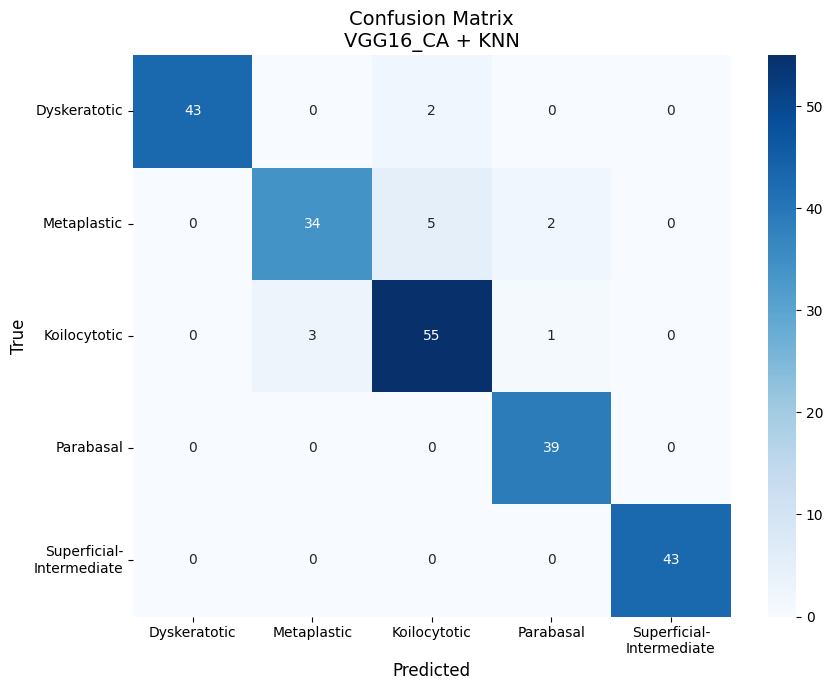

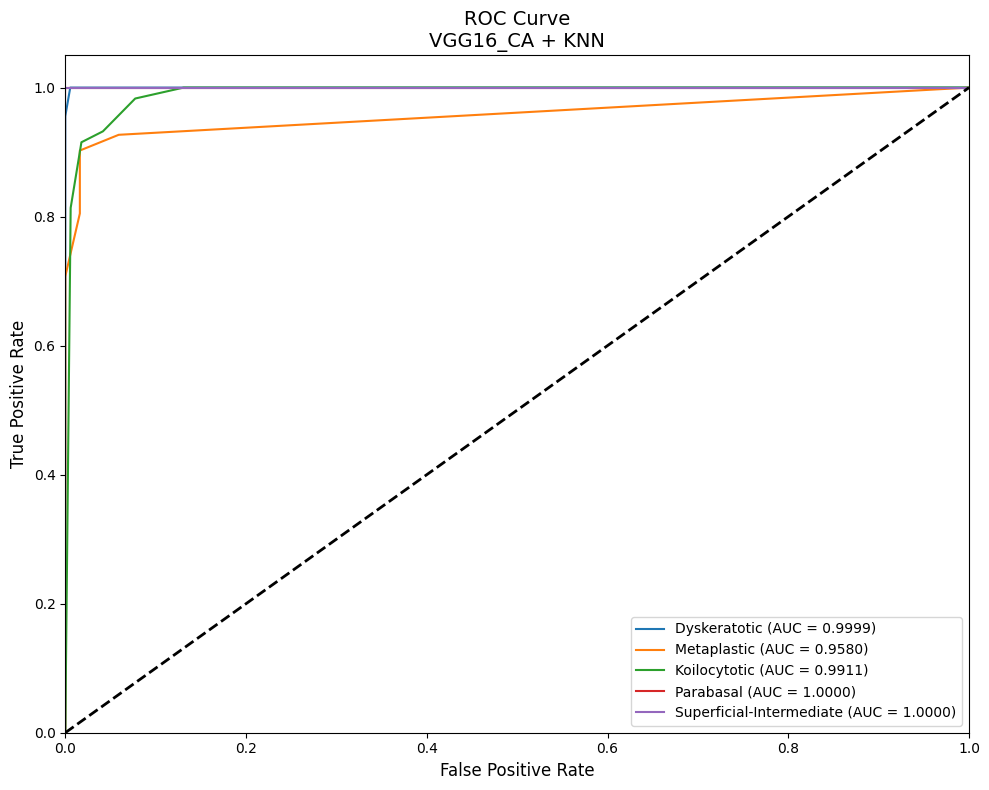


--- VGG16_CA + MLP ---
Test Accuracy       : 0.960352
Meta training time  : 0.801596 s
Test time per image : 0.000005 s

Classification Report:
                          precision    recall  f1-score   support

            Dyskeratotic   1.000000  0.955556  0.977273        45
             Metaplastic   0.926829  0.926829  0.926829        41
            Koilocytotic   0.932203  0.932203  0.932203        59
               Parabasal   0.951220  1.000000  0.975000        39
Superficial-Intermediate   1.000000  1.000000  1.000000        43

                accuracy                       0.960352       227
               macro avg   0.962050  0.962918  0.962261       227
            weighted avg   0.960782  0.960352  0.960362       227



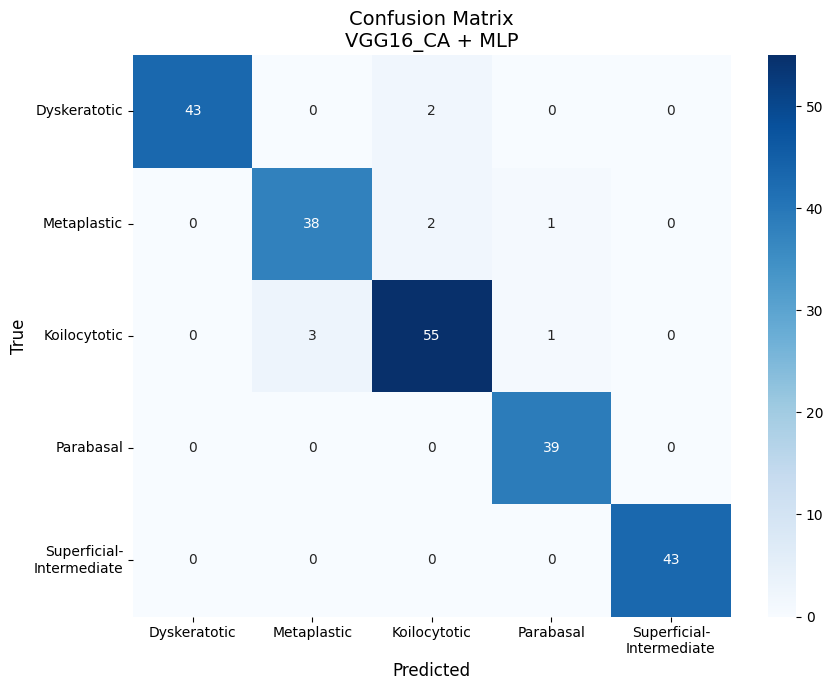

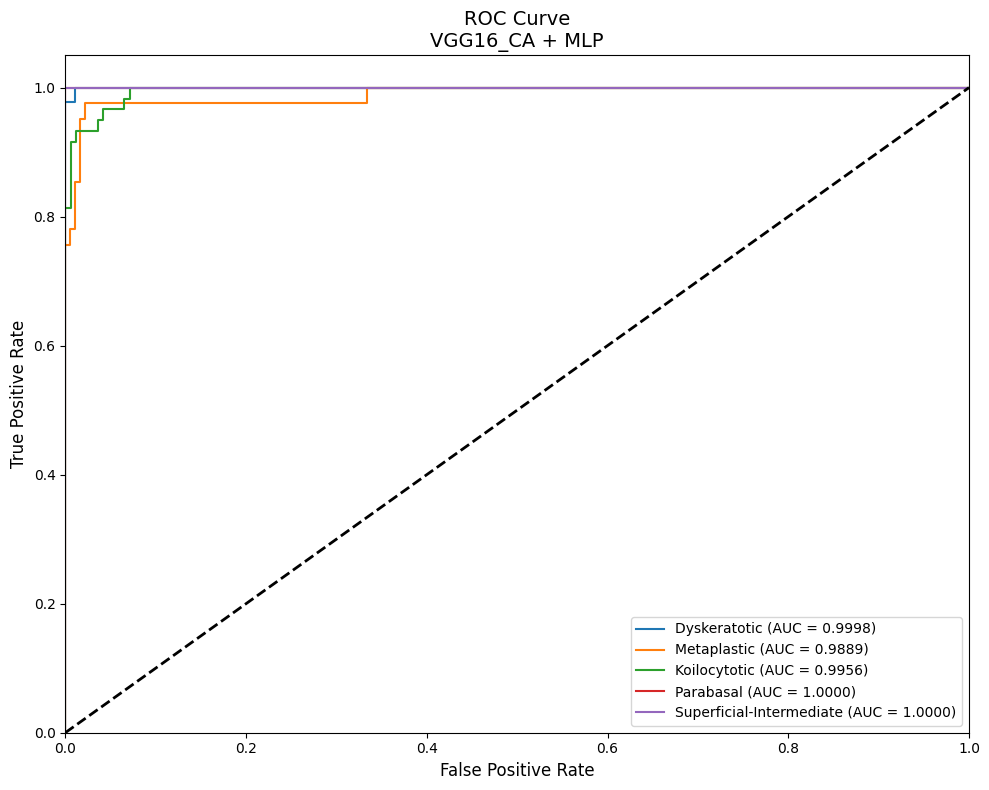


--- VGG16_CA + RandomForest ---
Test Accuracy       : 0.955947
Meta training time  : 0.752534 s
Test time per image : 0.000879 s

Classification Report:
                          precision    recall  f1-score   support

            Dyskeratotic   1.000000  0.955556  0.977273        45
             Metaplastic   0.971429  0.829268  0.894737        41
            Koilocytotic   0.892308  0.983051  0.935484        59
               Parabasal   0.951220  1.000000  0.975000        39
Superficial-Intermediate   1.000000  1.000000  1.000000        43

                accuracy                       0.955947       227
               macro avg   0.962991  0.953575  0.956499       227
            weighted avg   0.958468  0.955947  0.955419       227



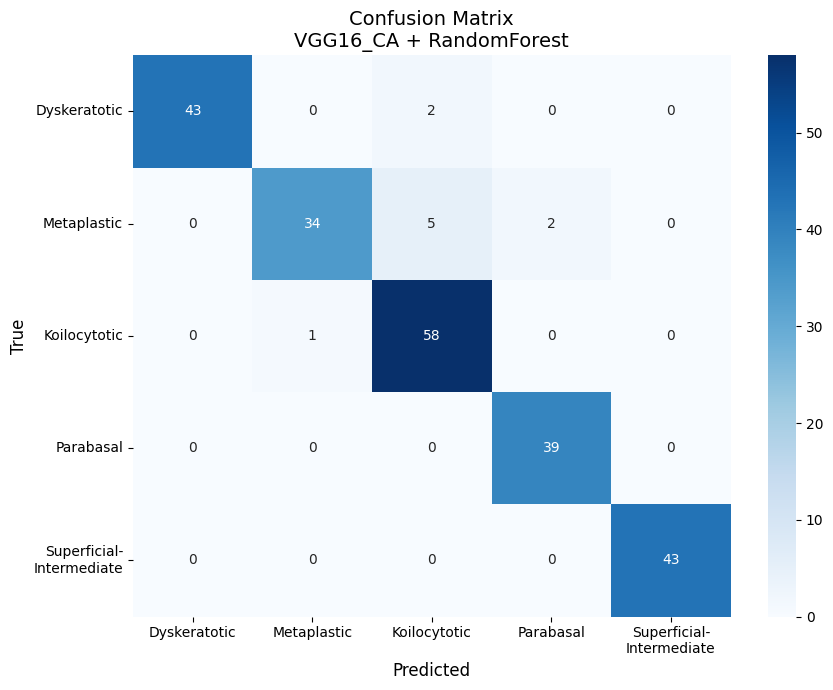

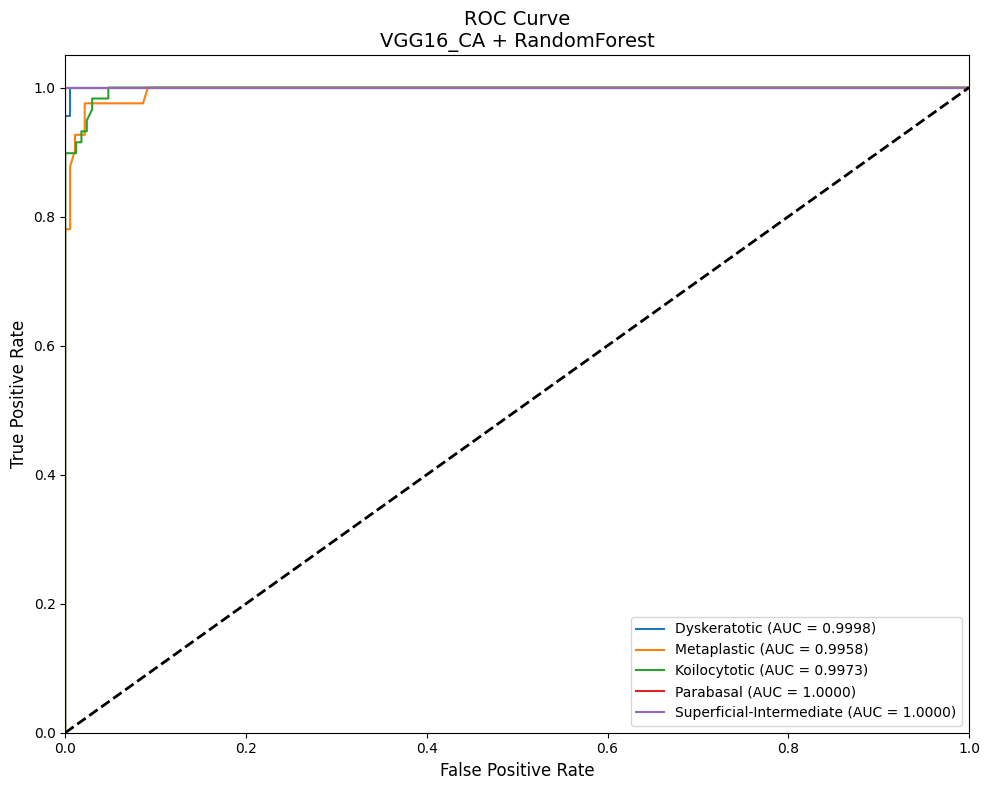


--- VGG16_CA + CatBoost ---
Test Accuracy       : 0.964758
Meta training time  : 1.219592 s
Test time per image : 0.000013 s

Classification Report:
                          precision    recall  f1-score   support

            Dyskeratotic   1.000000  0.955556  0.977273        45
             Metaplastic   1.000000  0.853659  0.921053        41
            Koilocytotic   0.907692  1.000000  0.951613        59
               Parabasal   0.951220  1.000000  0.975000        39
Superficial-Intermediate   1.000000  1.000000  1.000000        43

                accuracy                       0.964758       227
               macro avg   0.971782  0.961843  0.964988       227
            weighted avg   0.967627  0.964758  0.964364       227



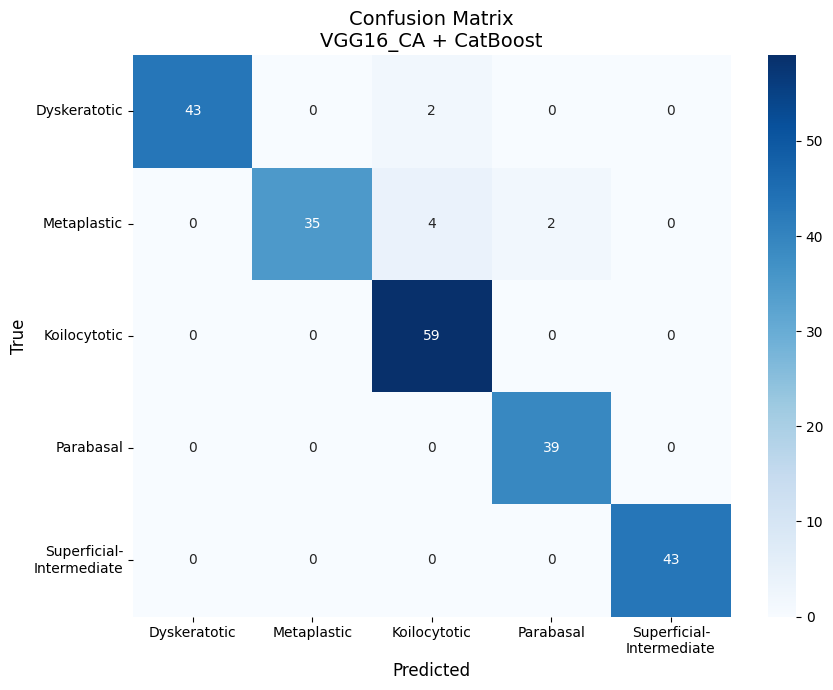

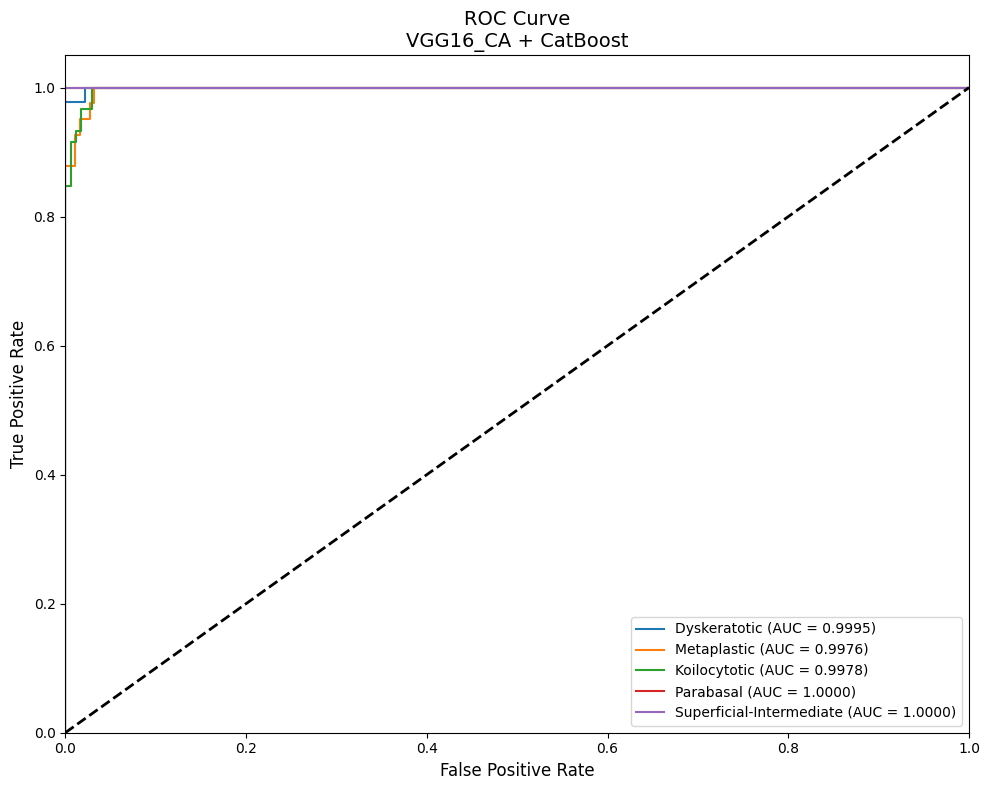

In [13]:
run_meta_classifiers("VGG16_CA", show_plots=True)

### DenseNet_CA

In [14]:
run_meta_classifiers("DenseNet_CA")

DenseNet_CA + Meta-Classifiers (base accuracy on test: 0.951542)

--- DenseNet_CA + KNN ---
Test Accuracy       : 0.960352
Meta training time  : 0.002375 s
Test time per image : 0.000023 s

Classification Report:
                          precision    recall  f1-score   support

            Dyskeratotic   1.000000  0.911111  0.953488        45
             Metaplastic   0.975000  0.951220  0.962963        41
            Koilocytotic   0.903226  0.949153  0.925620        59
               Parabasal   0.975000  1.000000  0.987342        39
Superficial-Intermediate   0.977273  1.000000  0.988506        43

                accuracy                       0.960352       227
               macro avg   0.966100  0.962297  0.963584       227
            weighted avg   0.961731  0.960352  0.960406       227


--- DenseNet_CA + MLP ---
Test Accuracy       : 0.951542
Meta training time  : 0.635411 s
Test time per image : 0.000006 s

Classification Report:
                          precision    rec

### VGG19_CA

In [15]:
run_meta_classifiers("VGG19_CA")

VGG19_CA + Meta-Classifiers (base accuracy on test: 0.955947)

--- VGG19_CA + KNN ---
Test Accuracy       : 0.960352
Meta training time  : 0.002661 s
Test time per image : 0.000020 s

Classification Report:
                          precision    recall  f1-score   support

            Dyskeratotic   0.977273  0.955556  0.966292        45
             Metaplastic   0.948718  0.902439  0.925000        41
            Koilocytotic   0.918033  0.949153  0.933333        59
               Parabasal   0.975000  1.000000  0.987342        39
Superficial-Intermediate   1.000000  1.000000  1.000000        43

                accuracy                       0.960352       227
               macro avg   0.963805  0.961429  0.962393       227
            weighted avg   0.960633  0.960352  0.960269       227


--- VGG19_CA + MLP ---
Test Accuracy       : 0.964758
Meta training time  : 0.489535 s
Test time per image : 0.000006 s

Classification Report:
                          precision    recall  f1-s

### Xception_CA

In [16]:
run_meta_classifiers("Xception_CA")

Xception_CA + Meta-Classifiers (base accuracy on test: 0.942731)

--- Xception_CA + KNN ---
Test Accuracy       : 0.942731
Meta training time  : 0.002538 s
Test time per image : 0.000021 s

Classification Report:
                          precision    recall  f1-score   support

            Dyskeratotic   1.000000  0.977778  0.988764        45
             Metaplastic   0.875000  0.853659  0.864198        41
            Koilocytotic   0.883333  0.898305  0.890756        59
               Parabasal   0.975000  1.000000  0.987342        39
Superficial-Intermediate   1.000000  1.000000  1.000000        43

                accuracy                       0.942731       227
               macro avg   0.946667  0.945948  0.946212       227
            weighted avg   0.942805  0.942731  0.942676       227


--- Xception_CA + MLP ---
Test Accuracy       : 0.947137
Meta training time  : 0.889233 s
Test time per image : 0.000005 s

Classification Report:
                          precision    rec

### Inception_CA

In [17]:
run_meta_classifiers("Inception_CA")

Inception_CA + Meta-Classifiers (base accuracy on test: 0.942731)

--- Inception_CA + KNN ---
Test Accuracy       : 0.955947
Meta training time  : 0.003481 s
Test time per image : 0.000020 s

Classification Report:
                          precision    recall  f1-score   support

            Dyskeratotic   0.957447  1.000000  0.978261        45
             Metaplastic   0.925000  0.902439  0.913580        41
            Koilocytotic   0.946429  0.898305  0.921739        59
               Parabasal   0.975000  1.000000  0.987342        39
Superficial-Intermediate   0.977273  1.000000  0.988506        43

                accuracy                       0.955947       227
               macro avg   0.956230  0.960149  0.957886       227
            weighted avg   0.955494  0.955947  0.955389       227


--- Inception_CA + MLP ---
Test Accuracy       : 0.951542
Meta training time  : 0.914376 s
Test time per image : 0.000006 s

Classification Report:
                          precision    

### MobileNet_CA

In [18]:
run_meta_classifiers("MobileNet_CA")

MobileNet_CA + Meta-Classifiers (base accuracy on test: 0.925110)

--- MobileNet_CA + KNN ---
Test Accuracy       : 0.920705
Meta training time  : 0.003158 s
Test time per image : 0.000022 s

Classification Report:
                          precision    recall  f1-score   support

            Dyskeratotic   0.976190  0.911111  0.942529        45
             Metaplastic   0.875000  0.853659  0.864198        41
            Koilocytotic   0.864407  0.864407  0.864407        59
               Parabasal   0.951220  1.000000  0.975000        39
Superficial-Intermediate   0.955556  1.000000  0.977273        43

                accuracy                       0.920705       227
               macro avg   0.924474  0.925835  0.924681       227
            weighted avg   0.920661  0.920705  0.920236       227


--- MobileNet_CA + MLP ---
Test Accuracy       : 0.942731
Meta training time  : 0.909911 s
Test time per image : 0.000006 s

Classification Report:
                          precision    

## Stacked ensembles

In [19]:
def fit_stacked_ensemble(members):
    X_meta_val = np.hstack([val_predictions[name] for name in members])
    X_meta_test = np.hstack([test_predictions[name] for name in members])

    meta = LogisticRegression(max_iter=2000, random_state=42)
    meta.fit(X_meta_val, y_val_classes)

    start = time.time()
    probs = meta.predict_proba(X_meta_test)
    time_per_image = (time.time() - start) / len(X_test)
    return probs, time_per_image


cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)


def val_cv_accuracy(members):
    X_meta_val = np.hstack([val_predictions[name] for name in members])
    oof_pred = cross_val_predict(LogisticRegression(max_iter=2000, random_state=42),
                                 X_meta_val, y_val_classes, cv=cv, groups=groups_val)
    return accuracy_score(y_val_classes, oof_pred)

### All combinations of the CA models

In [33]:
ensemble_results = {}

for r in range(2, len(ca_models) + 1):
    for combo in combinations(ca_models, r):
        probs, _ = fit_stacked_ensemble(combo)
        ensemble_results[" + ".join(combo)] = {
            "size": r,
            "val_cv_accuracy": val_cv_accuracy(combo),
            "test_accuracy": accuracy_score(y_test_classes, np.argmax(probs, axis=1)),
            "predictions": probs,
        }

# rank by test accuracy 
ranked = sorted(ensemble_results.items(), key=lambda x: (-x[1]["test_accuracy"], x[1]["size"]))
ensemble_rank = {name: i for i, (name, _) in enumerate(ranked, 1)}

print(f"{len(ensemble_results)} ensembles evaluated\n")
print("Top 30 ensembles (ranked by validation CV accuracy)")
print(f"{'':4s}{'Ensemble':75s}  {'Val CV Acc':>10s}  {'Test Acc':>10s}")
print("-" * 105)
for i, (name, data) in enumerate(ranked[:30], 1):
    print(f"{i:2d}. {name:75s}  {data['val_cv_accuracy']:10.6f}  {data['test_accuracy']:10.6f}")

best_name, best_data = ranked[0]
print("\n" + "=" * 90)
print(f"SELECTED ENSEMBLE (by test): {best_name}")
print(f"Val CV Accuracy : {best_data['val_cv_accuracy']:.6f}")
print(f"Test Accuracy   : {best_data['test_accuracy']:.6f}")
print("=" * 90)
print(classification_report(y_test_classes, np.argmax(best_data["predictions"], axis=1),
                            target_names=class_names, digits=4))

120 ensembles evaluated

Top 30 ensembles (ranked by validation CV accuracy)
    Ensemble                                                                     Val CV Acc    Test Acc
---------------------------------------------------------------------------------------------------------
 1. VGG16_CA + VGG19_CA + ResNet50_CA + Inception_CA                               0.961905    0.986784
 2. VGG16_CA + VGG19_CA + ResNet50_CA + DenseNet_CA + Inception_CA                 0.958730    0.986784
 3. VGG19_CA + ResNet50_CA + DenseNet_CA + Inception_CA                            0.961905    0.982379
 4. VGG19_CA + ResNet50_CA + Inception_CA                                          0.960317    0.977974
 5. VGG16_CA + VGG19_CA + ResNet50_CA + MobileNet_CA                               0.953968    0.977974
 6. VGG16_CA + VGG19_CA + MobileNet_CA + Inception_CA                              0.957143    0.977974
 7. VGG19_CA + ResNet50_CA + MobileNet_CA + Inception_CA                           0.9587

In [21]:
def evaluate_pair_ensemble(members):
    name = " + ".join(members)
    probs, time_per_image = fit_stacked_ensemble(members)
    y_pred = np.argmax(probs, axis=1)

    print(f"Stacked Ensemble: {name}")
    print(f"Val CV Accuracy     : {ensemble_results[name]['val_cv_accuracy']:.6f} ")
    print(f"Test Accuracy       : {accuracy_score(y_test_classes, y_pred):.6f}"
          f"(rank {ensemble_rank[name]} of {len(ensemble_results)})")
    print(f"Test time per image : {time_per_image:.6f} s")
    print("\nClassification Report:")
    print(classification_report(y_test_classes, y_pred, target_names=class_names, digits=6))

    save_name = "Ensemble_" + "_".join(members)
    plot_confusion_matrix(y_test_classes, y_pred, f'Ensemble: {name}', save_name)
    plot_roc_curves(y_test, probs, f'Ensemble: {name}', save_name)

#### VGG16_CA + VGG19_CA + ResNet50_CA + Inception_CA

Stacked Ensemble: VGG16_CA + VGG19_CA + ResNet50_CA + Inception_CA
Val CV Accuracy     : 0.961905 
Test Accuracy       : 0.986784(rank 1 of 120)
Test time per image : 0.000003 s

Classification Report:
                          precision    recall  f1-score   support

            Dyskeratotic   1.000000  0.977778  0.988764        45
             Metaplastic   1.000000  0.975610  0.987654        41
            Koilocytotic   0.966667  0.983051  0.974790        59
               Parabasal   1.000000  1.000000  1.000000        39
Superficial-Intermediate   0.977273  1.000000  0.988506        43

                accuracy                       0.986784       227
               macro avg   0.988788  0.987288  0.987943       227
            weighted avg   0.987031  0.986784  0.986813       227



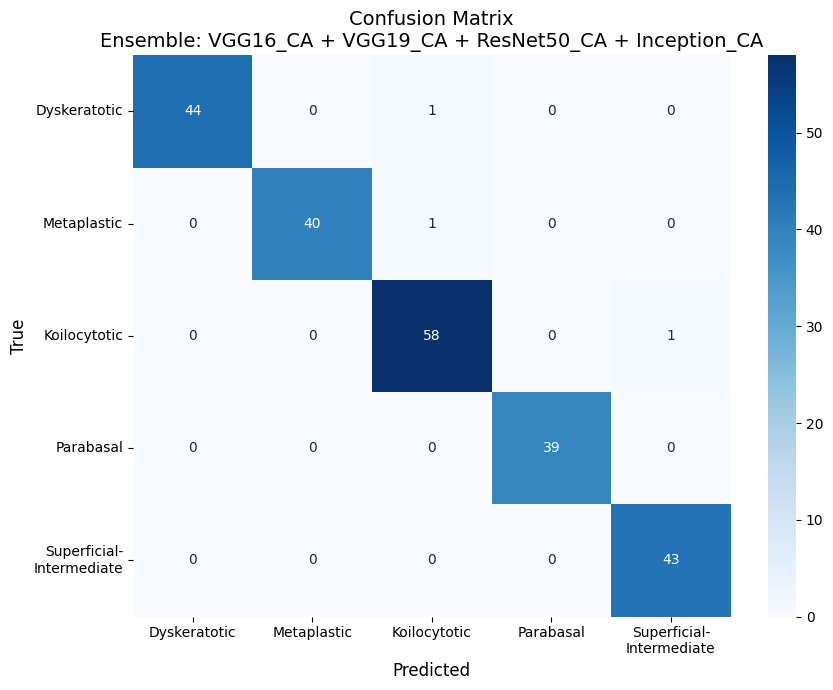

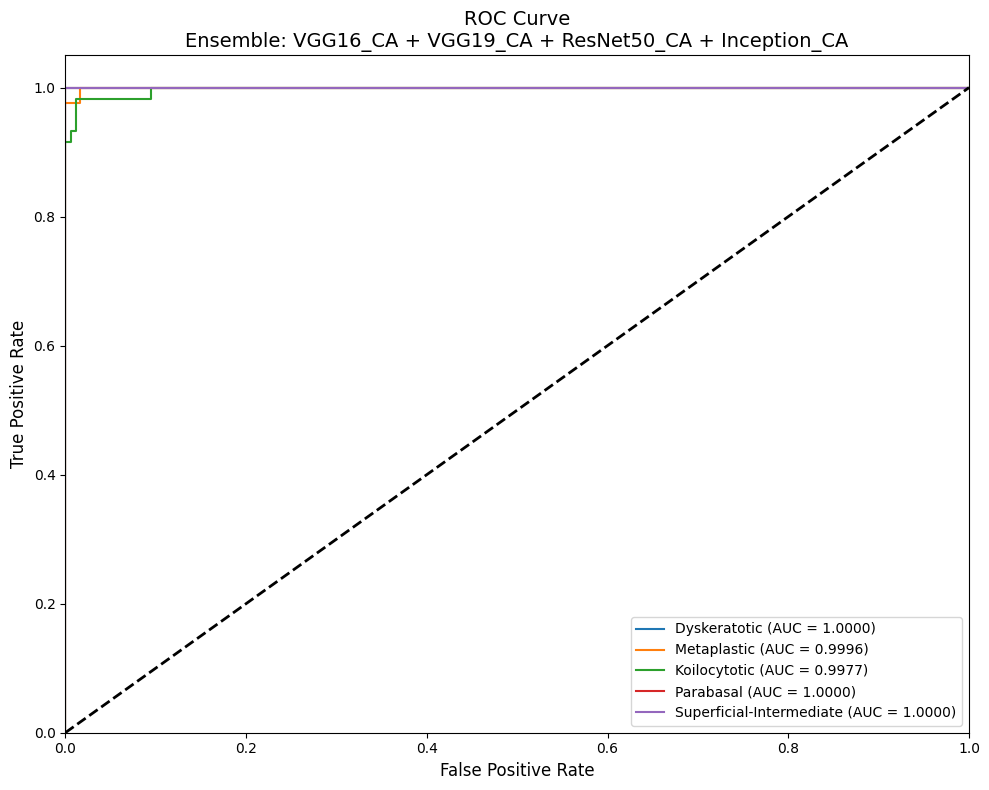

In [31]:
evaluate_pair_ensemble(['VGG16_CA','VGG19_CA','ResNet50_CA','Inception_CA',])

#### VGG19_CA + ResNet50_CA + DenseNet_CA + Inception_CA

Stacked Ensemble: VGG19_CA + ResNet50_CA + DenseNet_CA + Inception_CA
Val CV Accuracy     : 0.961905 
Test Accuracy       : 0.982379(rank 3 of 120)
Test time per image : 0.000003 s

Classification Report:
                          precision    recall  f1-score   support

            Dyskeratotic   1.000000  0.977778  0.988764        45
             Metaplastic   0.975610  0.975610  0.975610        41
            Koilocytotic   0.966102  0.966102  0.966102        59
               Parabasal   1.000000  1.000000  1.000000        39
Superficial-Intermediate   0.977273  1.000000  0.988506        43

                accuracy                       0.982379       227
               macro avg   0.983797  0.983898  0.983796       227
            weighted avg   0.982479  0.982379  0.982379       227



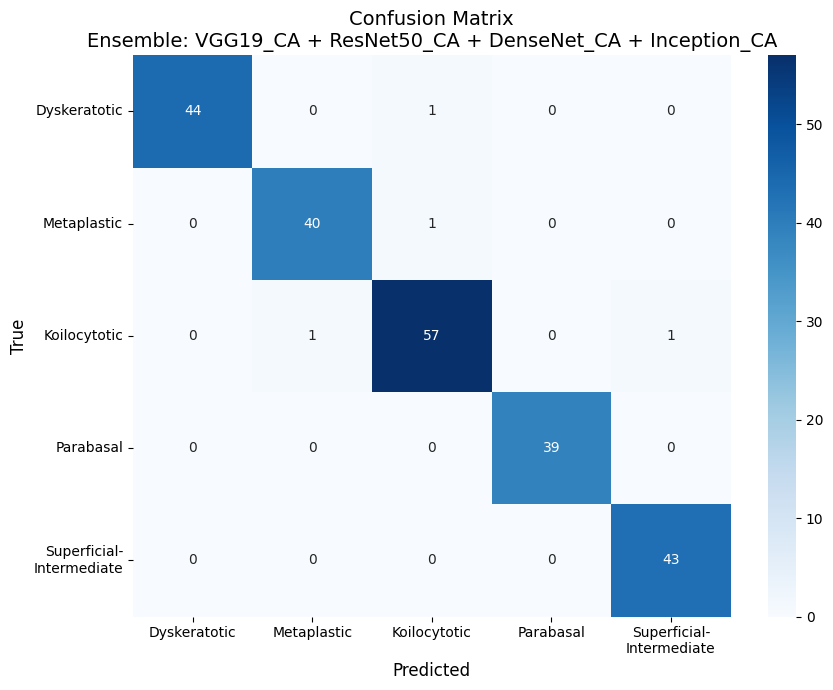

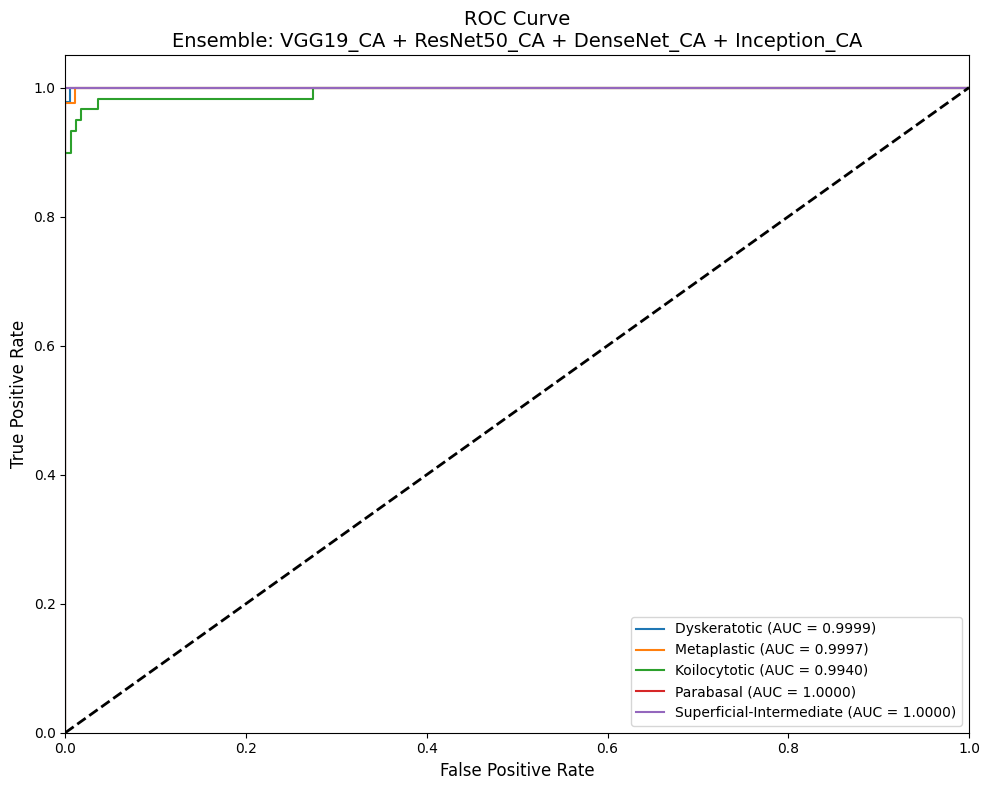

In [35]:
evaluate_pair_ensemble(['VGG19_CA','ResNet50_CA','DenseNet_CA','Inception_CA',])

#### VGG19_CA + ResNet50_CA + Inception_CA

Stacked Ensemble: VGG19_CA + ResNet50_CA + Inception_CA
Val CV Accuracy     : 0.960317 
Test Accuracy       : 0.977974(rank 4 of 120)
Test time per image : 0.000002 s

Classification Report:
                          precision    recall  f1-score   support

            Dyskeratotic   1.000000  0.977778  0.988764        45
             Metaplastic   1.000000  0.926829  0.962025        41
            Koilocytotic   0.935484  0.983051  0.958678        59
               Parabasal   1.000000  1.000000  1.000000        39
Superficial-Intermediate   0.977273  1.000000  0.988506        43

                accuracy                       0.977974       227
               macro avg   0.982551  0.977532  0.979595       227
            weighted avg   0.978926  0.977974  0.977996       227



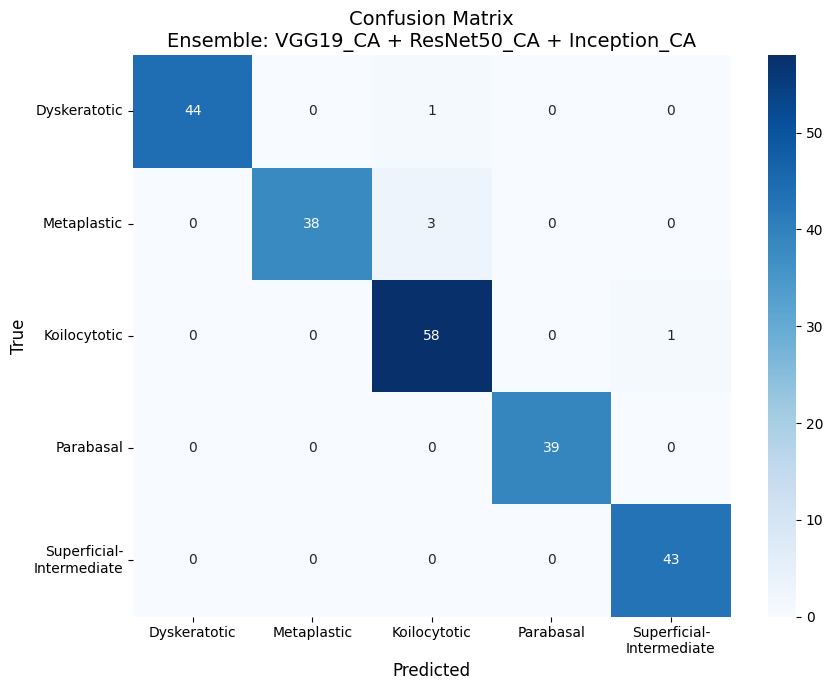

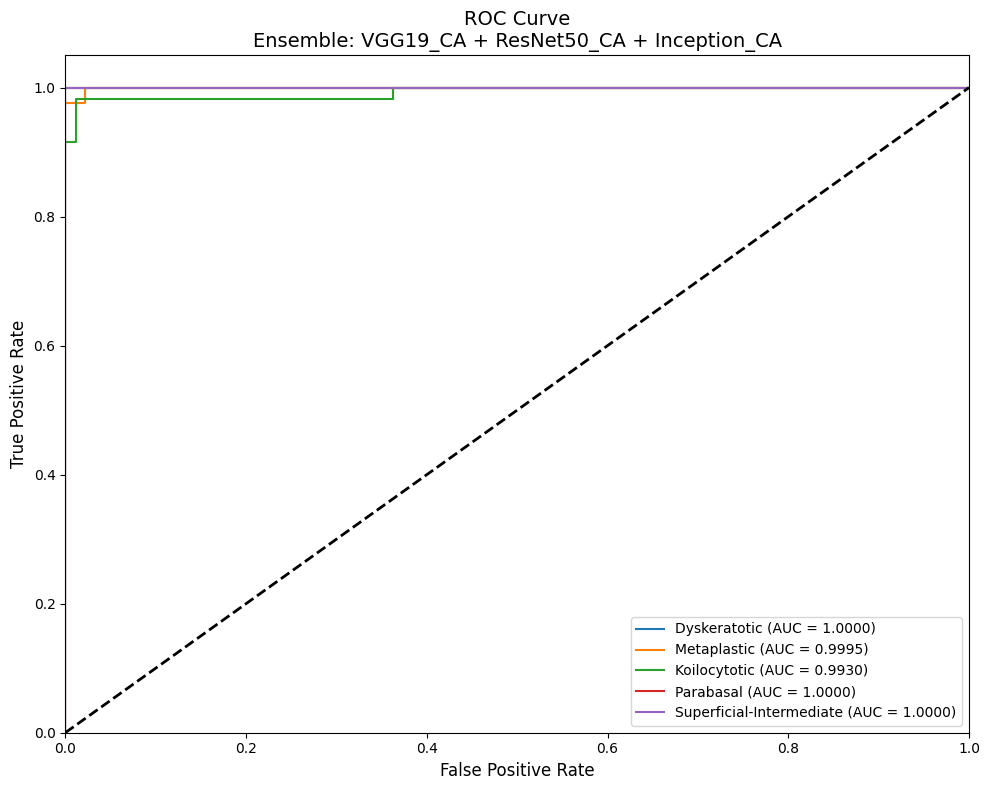

In [36]:
evaluate_pair_ensemble(['VGG19_CA','ResNet50_CA','Inception_CA',])

#### VGG16_CA + MobileNet_CA

Stacked Ensemble: VGG16_CA + MobileNet_CA
Val CV Accuracy     : 0.944444 
Test Accuracy       : 0.973568(rank 15 of 120)
Test time per image : 0.000002 s

Classification Report:
                          precision    recall  f1-score   support

            Dyskeratotic   1.000000  0.933333  0.965517        45
             Metaplastic   0.975000  0.951220  0.962963        41
            Koilocytotic   0.950820  0.983051  0.966667        59
               Parabasal   0.951220  1.000000  0.975000        39
Superficial-Intermediate   1.000000  1.000000  1.000000        43

                accuracy                       0.973568       227
               macro avg   0.975408  0.973521  0.974029       227
            weighted avg   0.974321  0.973568  0.973516       227



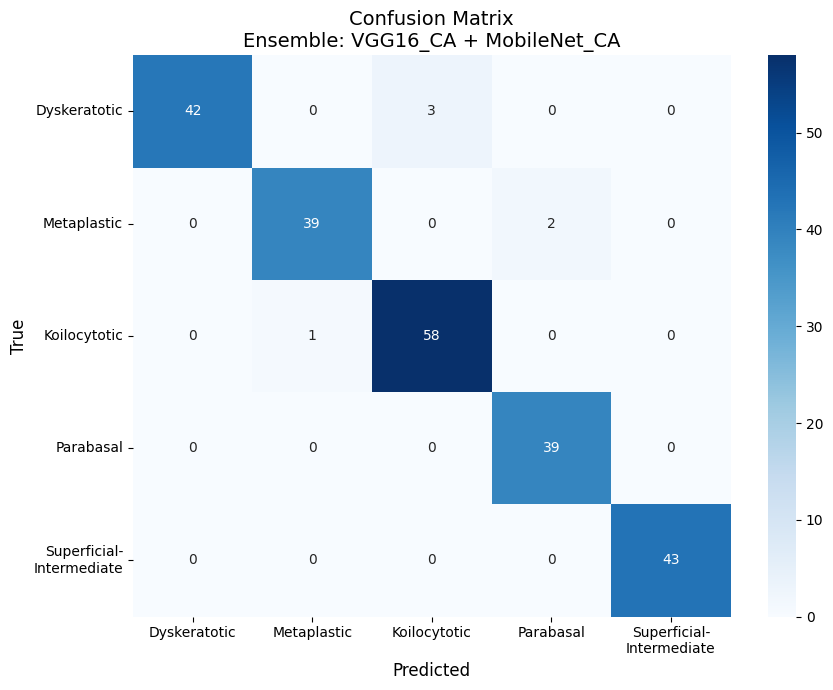

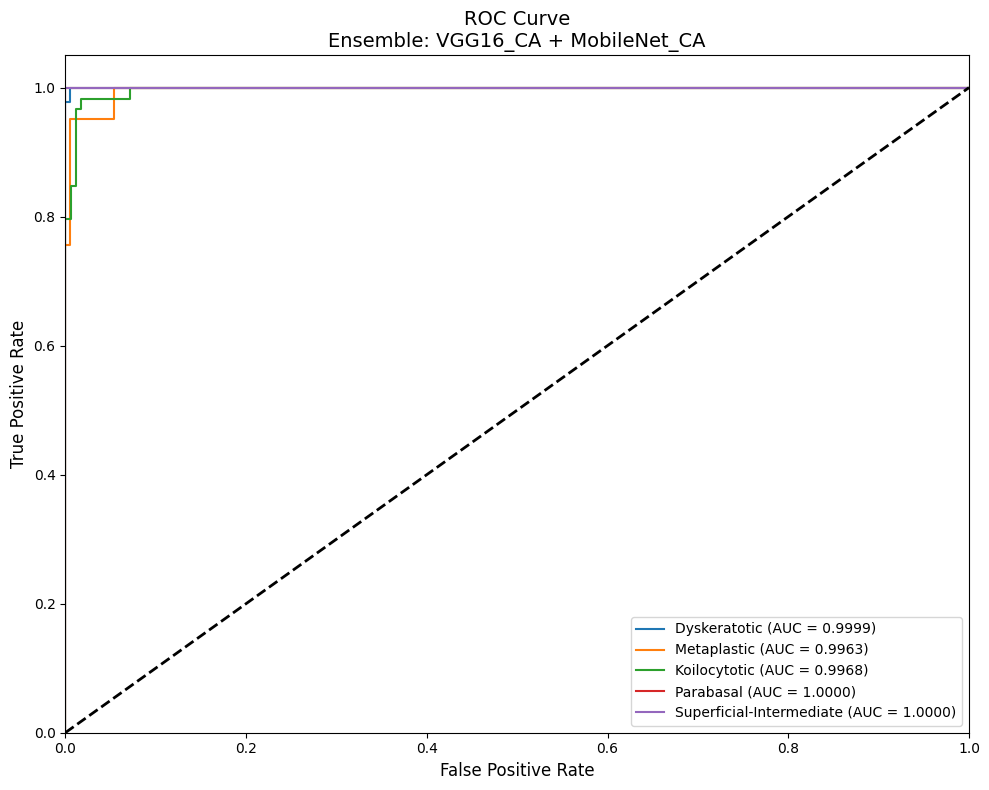

In [37]:
evaluate_pair_ensemble(['VGG16_CA', 'MobileNet_CA'])

#### VGG16_CA + ResNet50_CA

Stacked Ensemble: VGG16_CA + ResNet50_CA
Val CV Accuracy     : 0.944444 
Test Accuracy       : 0.973568(rank 14 of 120)
Test time per image : 0.000003 s

Classification Report:
                          precision    recall  f1-score   support

            Dyskeratotic   1.000000  0.955556  0.977273        45
             Metaplastic   1.000000  0.902439  0.948718        41
            Koilocytotic   0.921875  1.000000  0.959350        59
               Parabasal   0.975000  1.000000  0.987342        39
Superficial-Intermediate   1.000000  1.000000  1.000000        43

                accuracy                       0.973568       227
               macro avg   0.979375  0.971599  0.974536       227
            weighted avg   0.975399  0.973568  0.973492       227



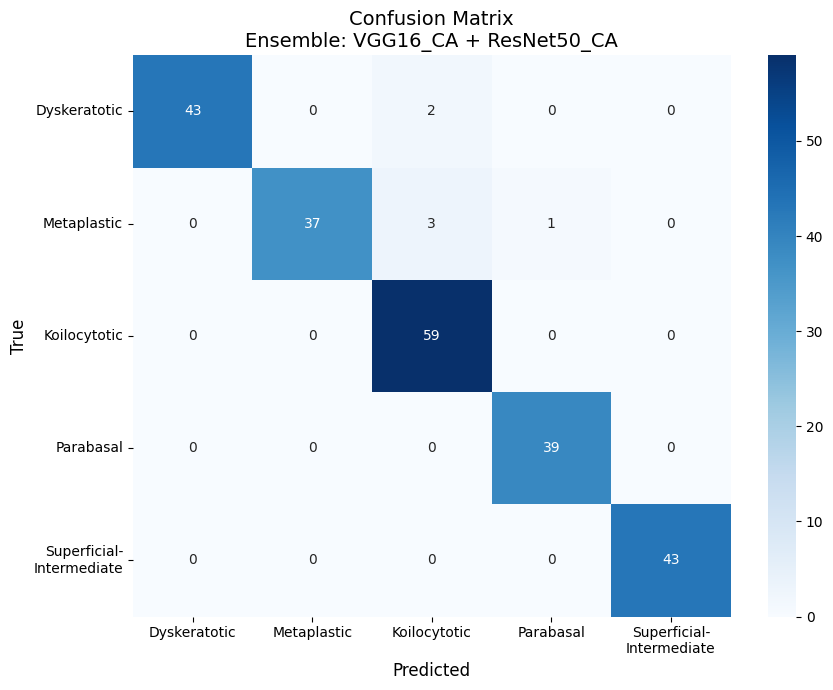

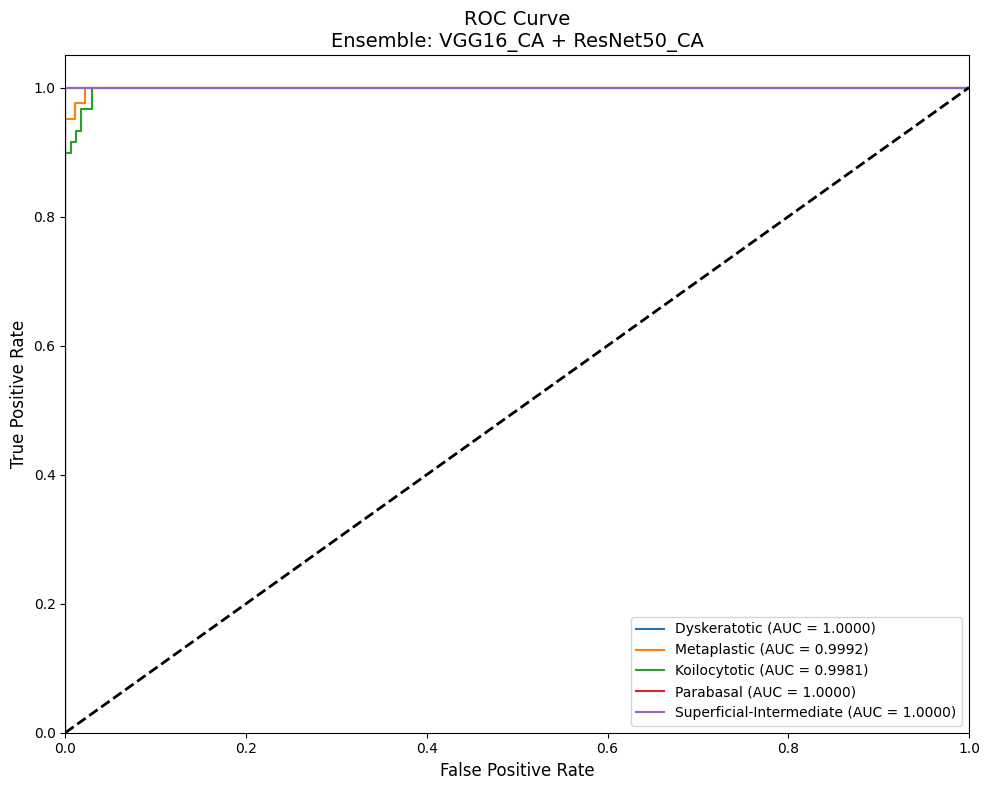

In [23]:
evaluate_pair_ensemble(['VGG16_CA', 'ResNet50_CA'])

## silhouette scores 

In [24]:
embedding_models = [name for name in model_info if name.endswith(("_GAP", "_CA"))]


def to_feature_matrix(features):
    if isinstance(features, (list, tuple)):
        features = features[-1]
    return features.reshape(features.shape[0], -1)


silhouette_results, tsne_embeddings = {}, {}

for name in embedding_models:
    K.clear_session()
    model = load_cervical_model(name)

    print(f"\n{name}: last layers ->", [(l.name, type(l).__name__) for l in model.layers[-5:]])
    feature_layer = model.layers[-3]  
    feature_model = Model(inputs=model.input, outputs=feature_layer.output)
    features = to_feature_matrix(feature_model.predict(X_test, batch_size=32, verbose=0))

    silhouette_results[name] = silhouette_score(features, y_test_classes)
    tsne_embeddings[name] = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(features)

    print(f"{name} (layer: {feature_layer.name}, features: {features.shape[1]}) "
          f"Silhouette Score: {silhouette_results[name]:.4f}")
    del model, feature_model, features


VGG16_GAP: last layers -> [('dense_8', 'Dense'), ('dropout_2', 'Dropout'), ('dense_9', 'Dense'), ('dropout_3', 'Dropout'), ('dense_10', 'Dense')]
VGG16_GAP (layer: dense_9, features: 512) Silhouette Score: 0.5725



VGG19_GAP: last layers -> [('dense_8', 'Dense'), ('dropout_2', 'Dropout'), ('dense_9', 'Dense'), ('dropout_3', 'Dropout'), ('dense_10', 'Dense')]
VGG19_GAP (layer: dense_9, features: 512) Silhouette Score: 0.5422



ResNet50_GAP: last layers -> [('dense_8', 'Dense'), ('dropout_2', 'Dropout'), ('dense_9', 'Dense'), ('dropout_3', 'Dropout'), ('dense_10', 'Dense')]


ResNet50_GAP (layer: dense_9, features: 512) Silhouette Score: 0.5416



MobileNet_GAP: last layers -> [('dense_8', 'Dense'), ('dropout_2', 'Dropout'), ('dense_9', 'Dense'), ('dropout_3', 'Dropout'), ('dense_10', 'Dense')]


MobileNet_GAP (layer: dense_9, features: 512) Silhouette Score: 0.4363


... (6 outputs left out)


MobileNet_CA: last layers -> [('dense_3', 'Dense'), ('dropout', 'Dropout'), ('dense_4', 'Dense'), ('dropout_1', 'Dropout'), ('dense_5', 'Dense')]
MobileNet_CA (layer: dense_4, features: 512) Silhouette Score: 0.4627



DenseNet_CA: last layers -> [('dense_3', 'Dense'), ('dropout', 'Dropout'), ('dense_4', 'Dense'), ('dropout_1', 'Dropout'), ('dense_5', 'Dense')]
DenseNet_CA (layer: dense_4, features: 512) Silhouette Score: 0.5766



Xception_CA: last layers -> [('dense_3', 'Dense'), ('dropout', 'Dropout'), ('dense_4', 'Dense'), ('dropout_1', 'Dropout'), ('dense_5', 'Dense')]
Xception_CA (layer: dense_4, features: 512) Silhouette Score: 0.4861



Inception_CA: last layers -> [('dense_3', 'Dense'), ('dropout', 'Dropout'), ('dense_4', 'Dense'), ('dropout_1', 'Dropout'), ('dense_5', 'Dense')]
Inception_CA (layer: dense_4, features: 512) Silhouette Score: 0.4775


In [25]:
rows = []
for name, score in silhouette_results.items():
    backbone, variant = name.rsplit("_", 1)
    rows.append({"Model": backbone, "Type": variant, "Silhouette Score": score})

silhouette_table = (pd.DataFrame(rows)
                    .pivot(index="Model", columns="Type", values="Silhouette Score")
                    [["GAP", "CA"]])

print("Silhouette Score Comparison Table\n")
print(silhouette_table.round(4))

Silhouette Score Comparison Table

Type          GAP      CA
Model                    
DenseNet   0.5219  0.5766
Inception  0.4582  0.4775
MobileNet  0.4363  0.4627
ResNet50   0.5416  0.5677
VGG16      0.5725  0.6038
VGG19      0.5422  0.6080
Xception   0.4567  0.4861


## t-SNE 

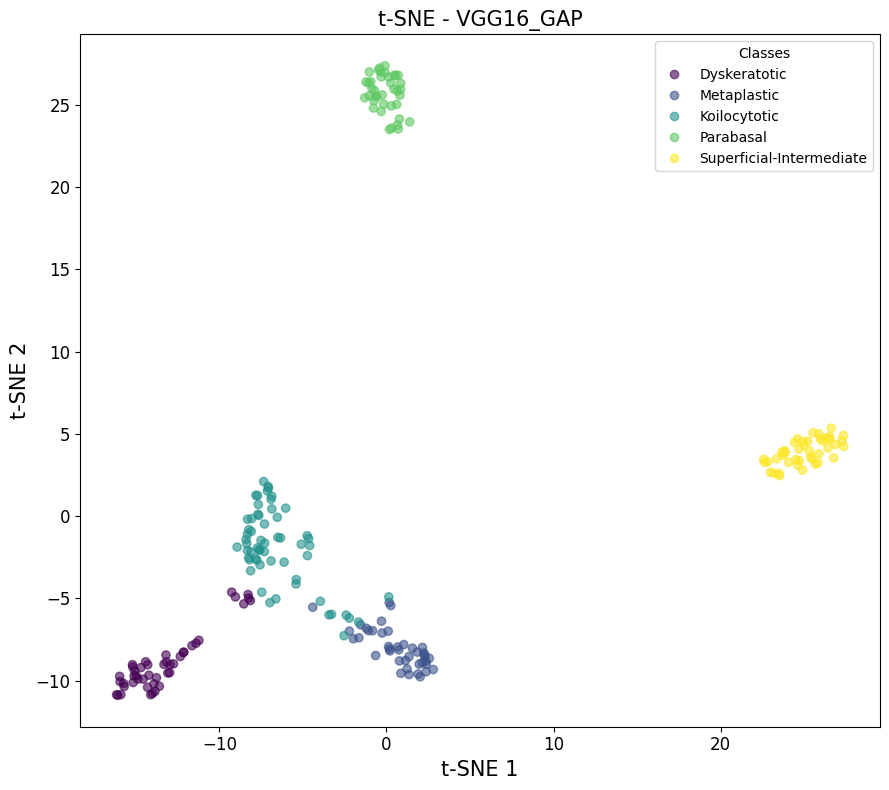

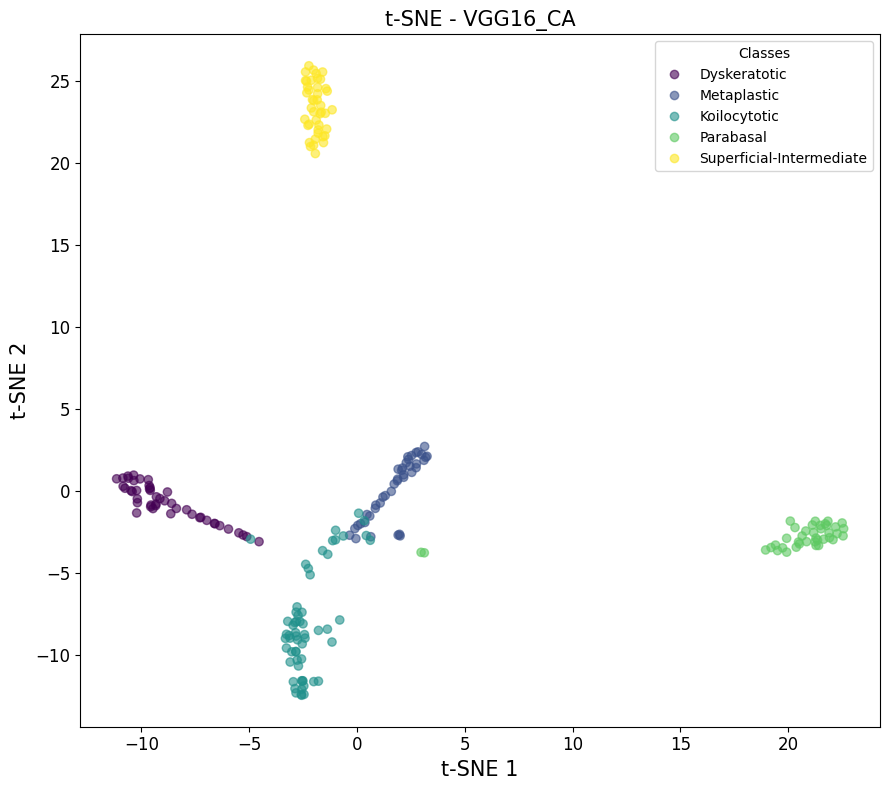

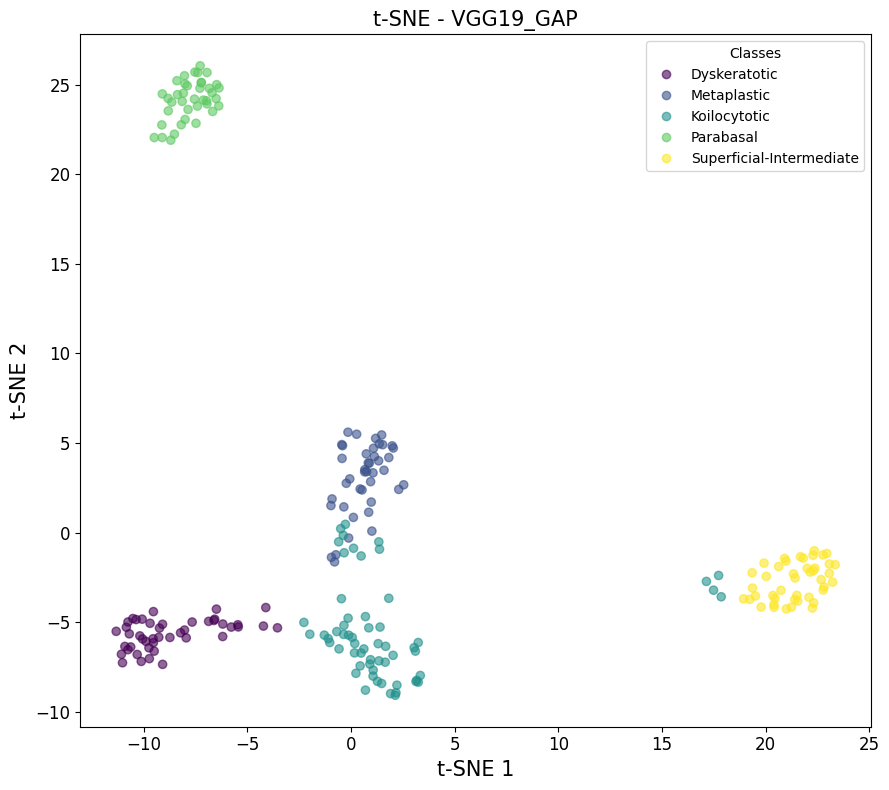

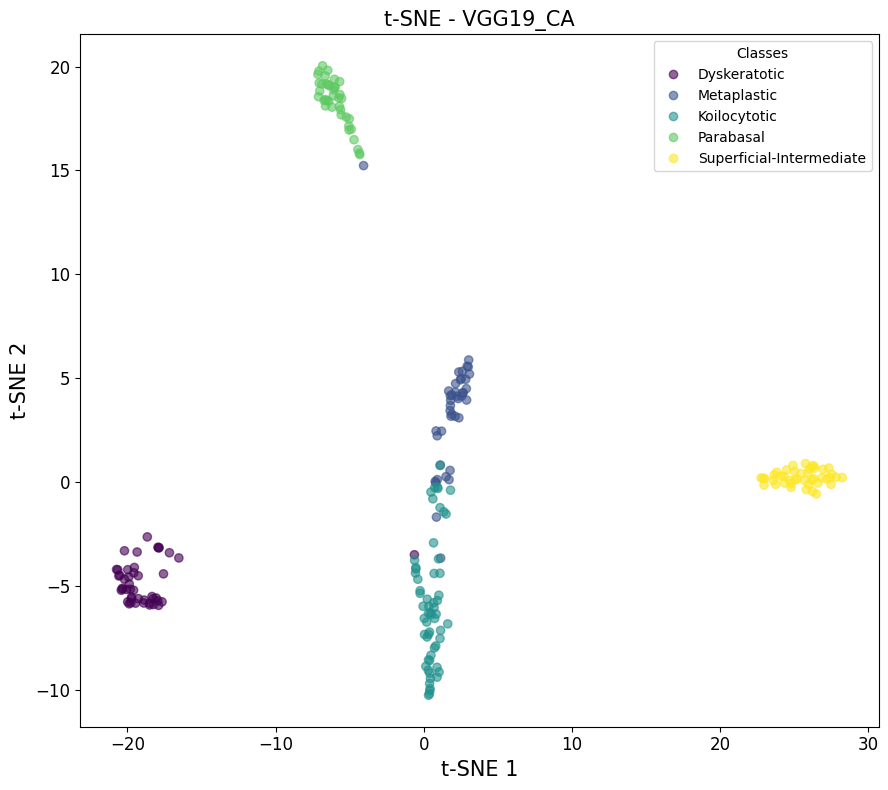

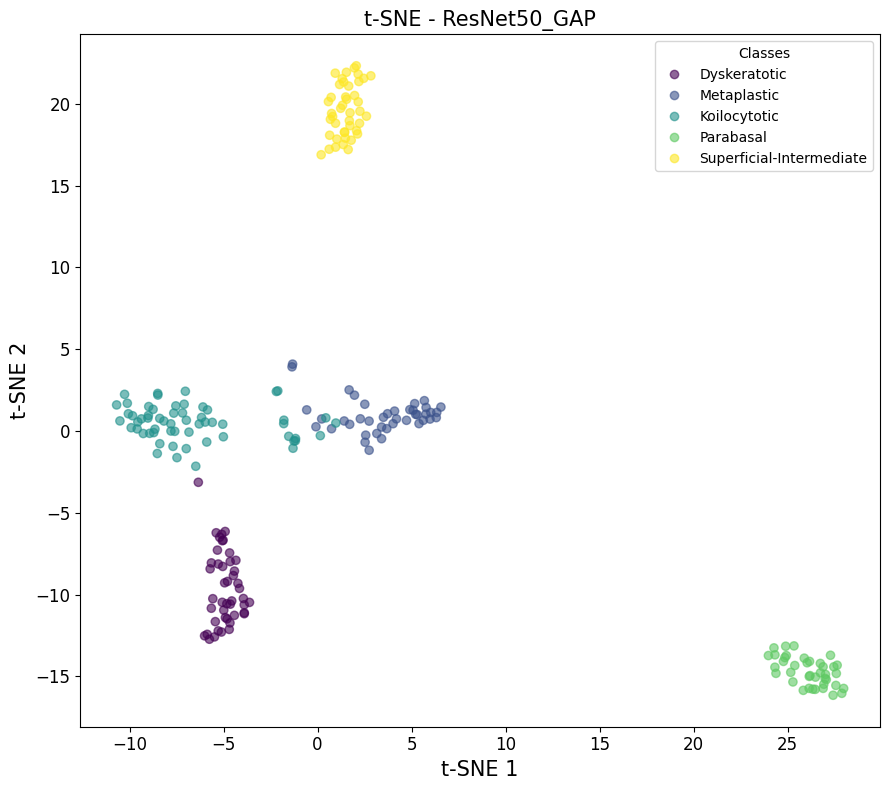

...

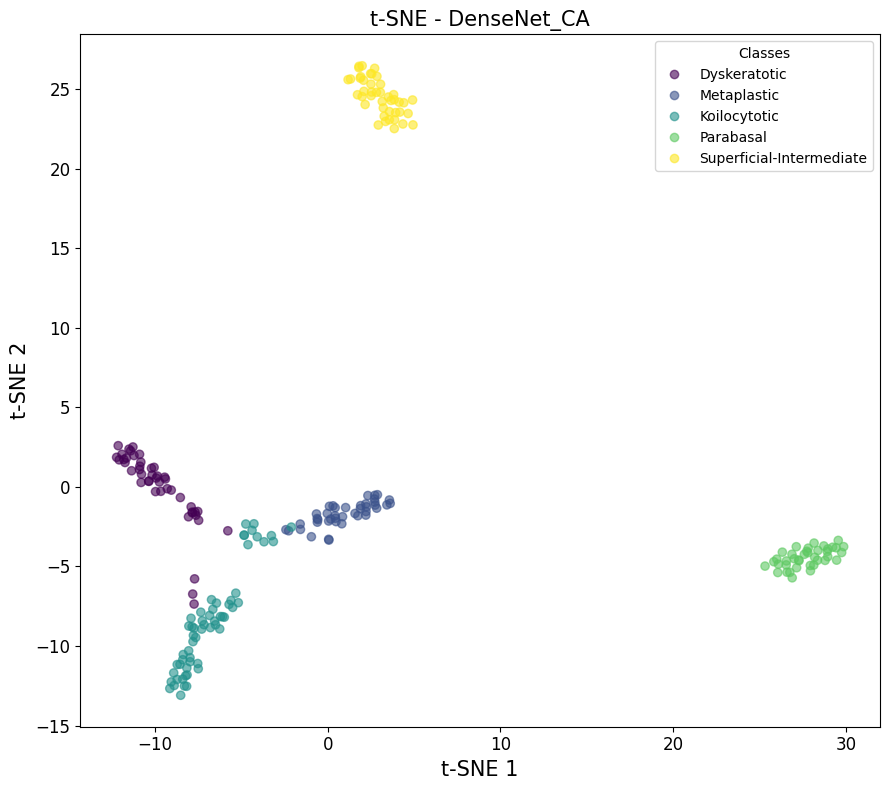

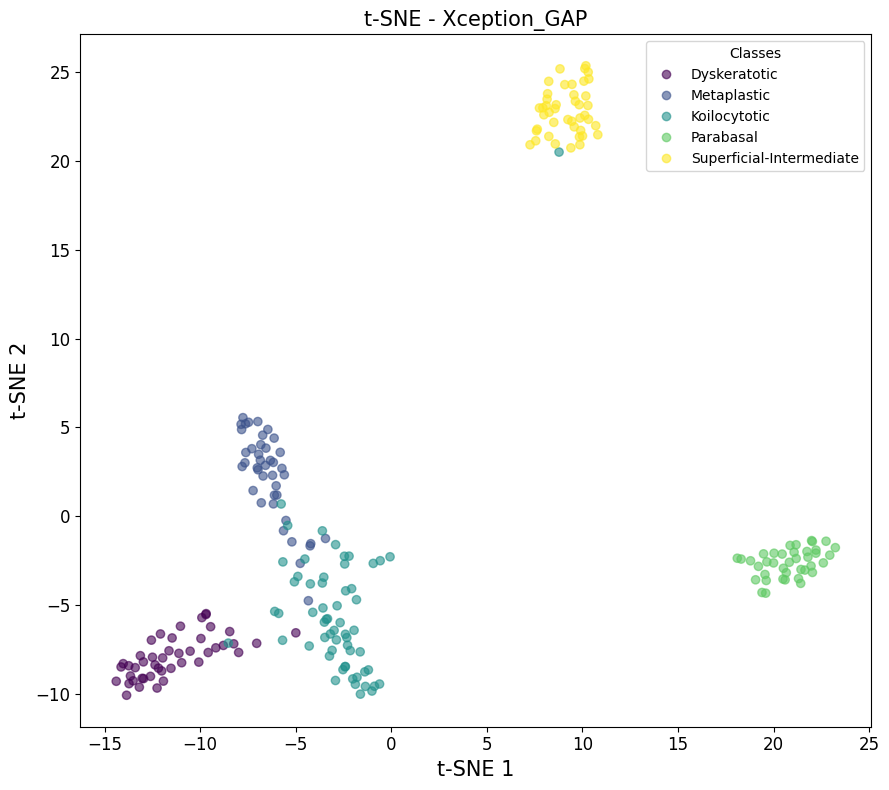

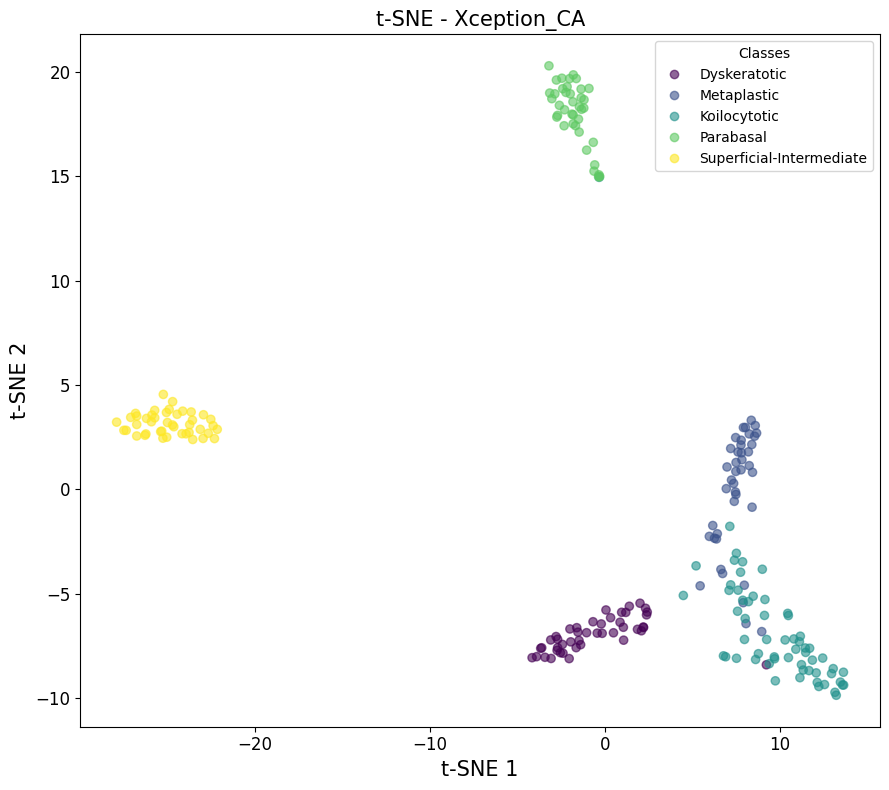

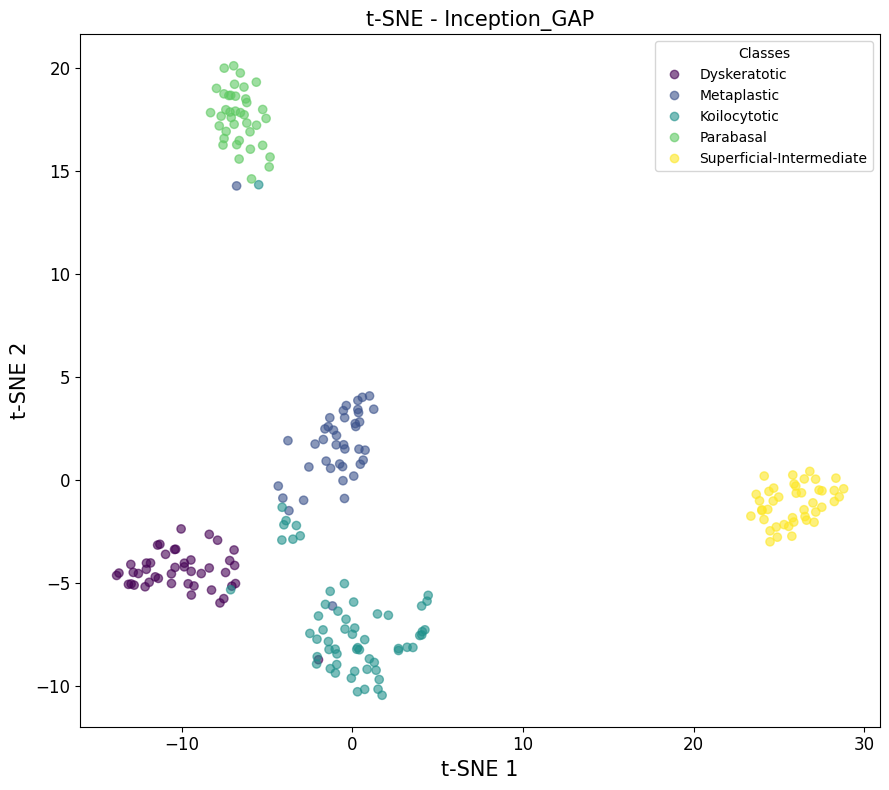

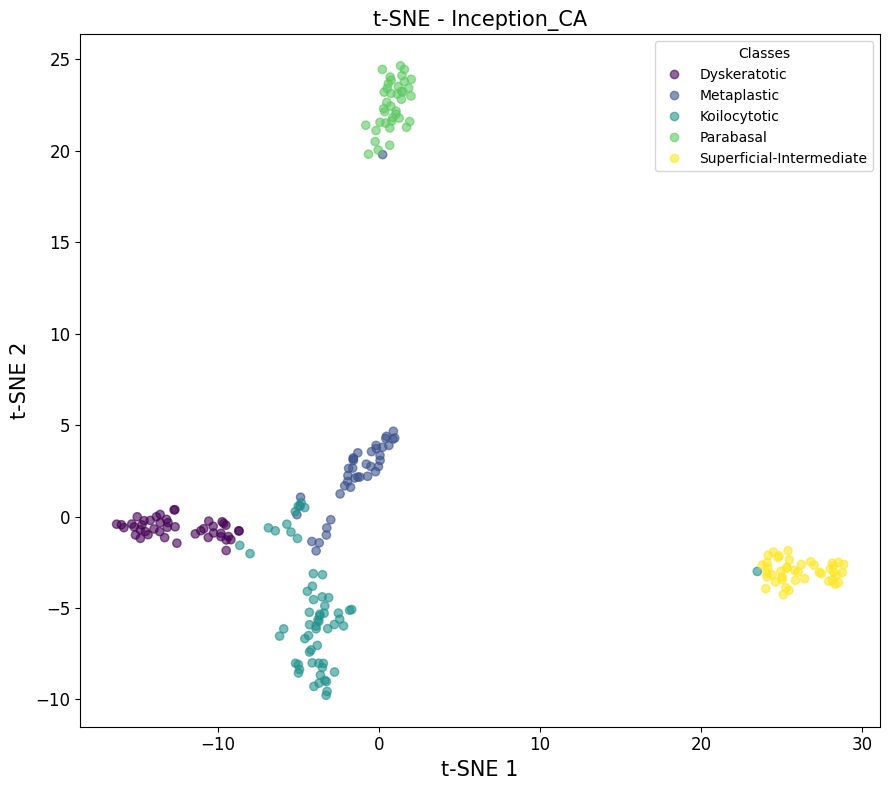

In [26]:
for backbone in versions:
    for variant in ["GAP", "CA"]:
        name = f"{backbone}_{variant}"
        emb = tsne_embeddings[name]
        fig, ax = plt.subplots(figsize=(9, 8))
        scatter = ax.scatter(emb[:, 0], emb[:, 1], c=y_test_classes, cmap='viridis', alpha=0.6)
        ax.set_title(f't-SNE - {name}', fontsize=15)
        ax.set_xlabel('t-SNE 1', fontsize=15)
        ax.set_ylabel('t-SNE 2', fontsize=15)
        ax.tick_params(labelsize=12)
        ax.legend(handles=scatter.legend_elements()[0], labels=class_names,
                  title="Classes", fontsize=10, title_fontsize=10)
        plt.tight_layout()
        plt.savefig(f'tsne_{name}.png', dpi=150)   
        plt.show()

## Paired McNemar’s test

In [27]:
from scipy.stats import binom

order = [("MobileNet", "MobileNet"), ("ResNet50", "ResNet50"), ("VGG16", "VGG16"),
         ("VGG19", "VGG19"), ("Xception", "Xception"),
         ("DenseNet", "DenseNet121"), ("Inception", "InceptionV3")]   

def mcnemar_exact(b, c):
    n, k = b + c, min(b, c)
    if n == 0:
        return 1.0, 1.0
    p_exact = min(1.0, 2 * binom.cdf(k, n, 0.5))
    p_mid = max(0.0, p_exact - binom.pmf(k, n, 0.5))
    return p_exact, p_mid

rows = []
n = len(y_test_classes)

for key, label in order:
    gap_ok = np.argmax(test_predictions[f"{key}_GAP"], axis=1) == y_test_classes
    ca_ok  = np.argmax(test_predictions[f"{key}_CA"],  axis=1) == y_test_classes

    both_correct = int(np.sum(gap_ok & ca_ok))
    b = int(np.sum(gap_ok & ~ca_ok))      # GAP correct, CA wrong
    c = int(np.sum(~gap_ok & ca_ok))      # GAP wrong,   CA correct
    both_wrong = int(np.sum(~gap_ok & ~ca_ok))
    assert both_correct + b + c + both_wrong == n

    p_exact, p_mid = mcnemar_exact(b, c)
    rows.append({
        "Backbone": label,
        "GAP Acc. (%)": 100 * gap_ok.mean(),
        "CA Acc. (%)": 100 * ca_ok.mean(),
        "Δ (pp)": 100 * (ca_ok.mean() - gap_ok.mean()),
        "Both correct": both_correct,
        "b": b, "c": c,
        "Both wrong": both_wrong,
        "McNemar p (exact)": p_exact,
        "Mid-p": p_mid,
    })

mcnemar_table = pd.DataFrame(rows).set_index("Backbone")

print(f"Paired McNemar's test, CA vs GAP per backbone (test partition, n = {n})")
print("b = GAP correct & CA wrong, c = GAP wrong & CA correct\n")
display(mcnemar_table.style.format({
    "GAP Acc. (%)": "{:.2f}", "CA Acc. (%)": "{:.2f}", "Δ (pp)": "{:+.2f}",
    "McNemar p (exact)": "{:.3f}", "Mid-p": "{:.3f}"}))

Paired McNemar's test, CA vs GAP per backbone (test partition, n = 227)
b = GAP correct & CA wrong, c = GAP wrong & CA correct



,GAP Acc. (%),CA Acc. (%),Δ (pp),Both correct,b,c,Both wrong,McNemar p (exact),Mid-p
Backbone,,,,,,,,,
MobileNet,90.31,92.51,+2.20,203,2,7,15,0.180,0.109
ResNet50,93.39,96.92,+3.52,212,0,8,7,0.008,0.004
VGG16,93.83,96.04,+2.20,208,5,10,4,0.302,0.210
VGG19,93.39,95.59,+2.20,203,9,14,1,0.405,0.307
Xception,91.63,94.27,+2.64,205,3,9,10,0.146,0.092
DenseNet121,93.83,95.15,+1.32,212,1,4,10,0.375,0.219
InceptionV3,91.63,94.27,+2.64,203,5,11,8,0.210,0.143


## Grad-Cam

In [28]:
def _last_call_tensor(layer, which):
    node = layer._inbound_nodes[-1]
    if which == "output":
        t = getattr(node, "output_tensors", None)
        if t is None:
            t = node.outputs
    else:
        t = node.input_tensors
    while isinstance(t, (list, tuple)) and len(t) == 1:
        t = t[0]
    return t


def build_gradcam_model(model):
    ca_layers = [l for l in model.layers if l.__class__.__name__ in ("ClusterAttentionBlock", "ASCFBlock")]
    if ca_layers:
        target = _last_call_tensor(ca_layers[-1], 'input')
    else:
        target = None
        for layer in reversed(model.layers):
            out = _last_call_tensor(layer, 'output')
            if not isinstance(out, (list, tuple)) and len(out.shape) == 4:
                target = out
                break
    if target is None:
        raise ValueError("No 4-D feature map found in the model")

    last = model.layers[-1]
    act_name = getattr(getattr(last, "activation", None), "__name__", "")
    if isinstance(last, tf.keras.layers.Dense) and act_name == "softmax":
        kind, head, aux = "dense", [np.asarray(w) for w in last.get_weights()], _last_call_tensor(last, 'input')
    elif isinstance(last, tf.keras.layers.Softmax) or (
            isinstance(last, tf.keras.layers.Activation) and act_name == "softmax"):
        kind, head, aux = "logits", None, _last_call_tensor(last, 'input')
    else:
        kind, head, aux = "log", None, model.output
    return Model(model.inputs, [target, aux]), kind, head


def gradcam_batch(model, images, targets=None):
    grad_model, kind, head = build_gradcam_model(model)
    x = tf.convert_to_tensor(np.asarray(images), dtype=tf.float32)
    with tf.GradientTape() as tape:
        feat, aux = grad_model(x, training=False)
        if kind == "dense":
            logits = tf.matmul(aux, head[0]) + (head[1] if len(head) > 1 else 0.0)
        elif kind == "logits":
            logits = aux
        else:
            logits = tf.math.log(aux + 1e-10)
        preds = tf.argmax(logits, axis=1).numpy()
        tgt = preds if targets is None else np.asarray(targets).astype(int)
        score = tf.reduce_sum(logits * tf.one_hot(tgt, logits.shape[-1]))
    grads = tape.gradient(score, feat)
    if grads is None:
        raise RuntimeError("No gradient reached the feature map")

    # sanity check: the reconstructed logits must reproduce the model's own predictions
    ref = np.argmax(model.predict(np.asarray(images), verbose=0), axis=1)
    assert np.array_equal(ref, preds), "Logit path does not match model.predict"

    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(feat * weights, axis=-1)).numpy()
    cam = cam / (cam.max(axis=(1, 2), keepdims=True) + 1e-8)
    return cam, preds, tgt


# ---------------------------------------------------------------------------------------------
# Test images (one per class, deterministic) and plotting / caching helpers
# ---------------------------------------------------------------------------------------------
gradcam_idx = np.array([np.where(y_test_classes == c)[0][0] for c in range(num_classes)])
X_gradcam = X_test[gradcam_idx]
print("Grad-CAM test indices:", gradcam_idx, "-> true classes:", [class_names[y_test_classes[i]] for i in gradcam_idx])

gradcam_cache = {}


def run_gradcam(name, targets=None):
    key = (name, None if targets is None else tuple(int(t) for t in targets))
    if key not in gradcam_cache:
        K.clear_session()
        model = load_cervical_model(name)
        cam, preds, tgt = gradcam_batch(model, X_gradcam, targets)
        print(f"  {name}: feature map {cam.shape[1]}x{cam.shape[2]} | predictions {[class_names[p][:4] for p in preds]}")
        gradcam_cache[key] = (cam, preds, tgt)
        del model
    return gradcam_cache[key]


def show_gradcam(title, heatmaps):
    n = len(gradcam_idx)
    fig, axes = plt.subplots(2, n, figsize=(4 * n, 6))
    fig.suptitle(title, fontsize=16)

    for i, idx in enumerate(gradcam_idx):
        img = X_test[idx]
        true_label = y_test_classes[idx]
        img_norm = (img - img.min()) / (img.max() - img.min() + 1e-8)
        img_norm = np.uint8(255 * img_norm)

        heatmap_resized = cv2.resize(heatmaps[i], (img.shape[1], img.shape[0]))
        heatmap_uint8 = np.uint8(255 * heatmap_resized)
        heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
        heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
        superimposed_img = cv2.addWeighted(img_norm, 0.6, heatmap_color, 0.4, 0)

        axes[0, i].imshow(img_norm)
        axes[0, i].set_title(f"{wrapped_class_names[true_label]}\n\nOriginal")   
        axes[0, i].axis('off')

        axes[1, i].imshow(superimposed_img)
        axes[1, i].set_title("Grad-CAM")
        axes[1, i].axis('off')

    plt.tight_layout()
    plt.savefig("gradcam_" + title.replace(" ", "_").replace("+", "plus").replace(":", "") + ".png", dpi=150)
    plt.show()

Grad-CAM test indices: [  0  45  86 145 184] -> true classes: ['Dyskeratotic', 'Metaplastic', 'Koilocytotic', 'Parabasal', 'Superficial-Intermediate']



Generating Grad-CAM for: VGG16_GAP


  VGG16_GAP: feature map 7x7 | predictions ['Dysk', 'Meta', 'Koil', 'Para', 'Supe']


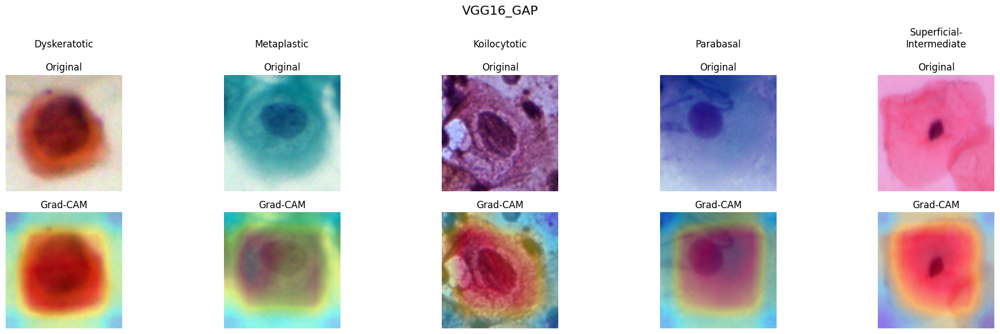


Generating Grad-CAM for: VGG16_CA


  VGG16_CA: feature map 7x7 | predictions ['Dysk', 'Meta', 'Koil', 'Para', 'Supe']


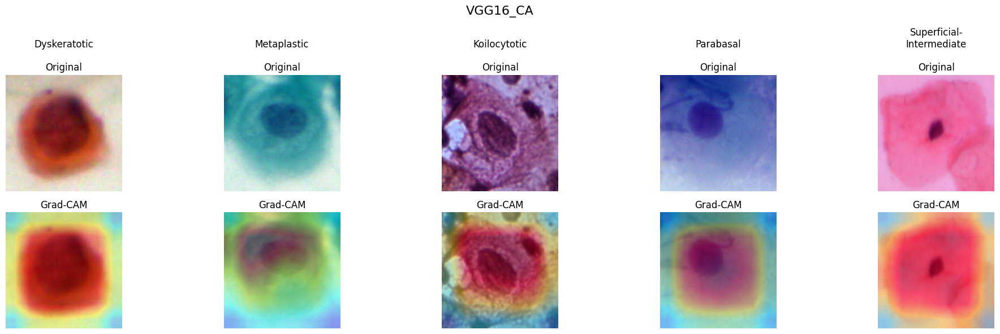


Generating Grad-CAM for: VGG19_GAP


  VGG19_GAP: feature map 7x7 | predictions ['Dysk', 'Meta', 'Koil', 'Para', 'Supe']


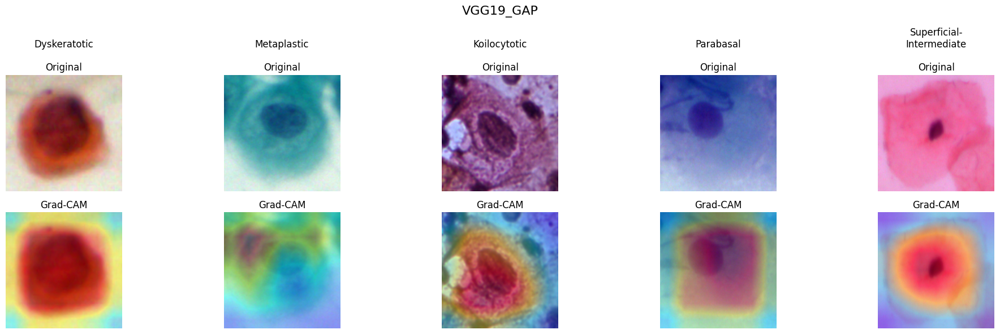


Generating Grad-CAM for: VGG19_CA


  VGG19_CA: feature map 7x7 | predictions ['Dysk', 'Meta', 'Koil', 'Para', 'Supe']


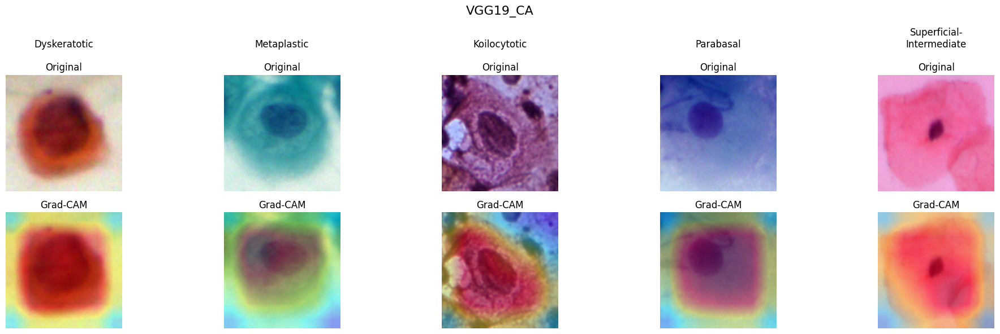


Generating Grad-CAM for: ResNet50_GAP


  ResNet50_GAP: feature map 7x7 | predictions ['Dysk', 'Meta', 'Koil', 'Para', 'Supe']


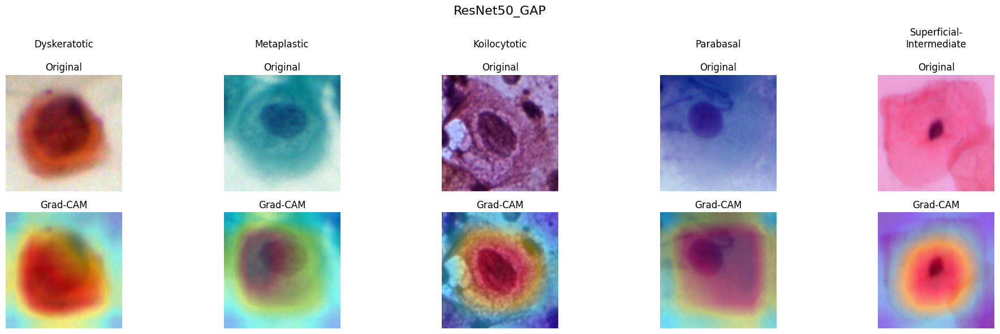


Generating Grad-CAM for: ResNet50_CA


  ResNet50_CA: feature map 7x7 | predictions ['Dysk', 'Meta', 'Koil', 'Para', 'Supe']


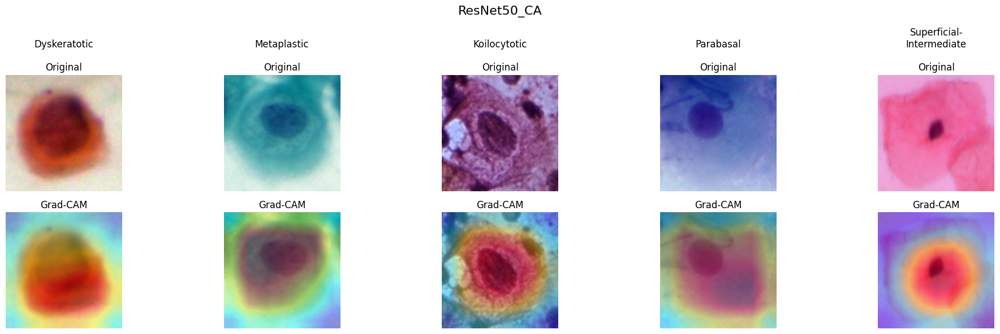


Generating Grad-CAM for: MobileNet_GAP


2026-11-14 07:55:56.119059: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-14 07:55:56.257329: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


  MobileNet_GAP: feature map 7x7 | predictions ['Dysk', 'Meta', 'Koil', 'Para', 'Supe']


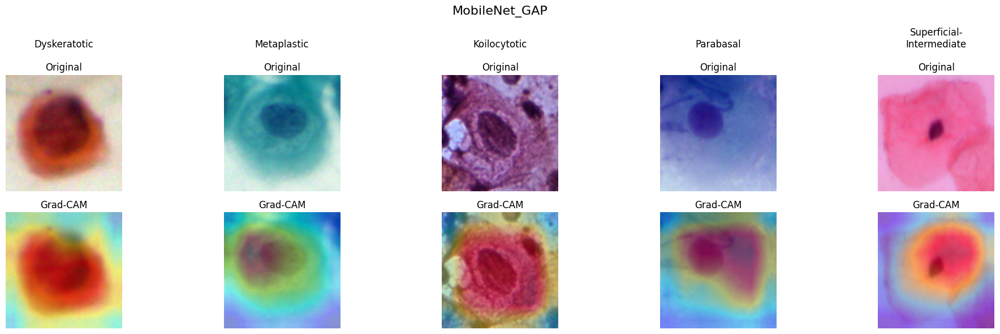


Generating Grad-CAM for: MobileNet_CA


  MobileNet_CA: feature map 7x7 | predictions ['Dysk', 'Meta', 'Koil', 'Para', 'Supe']


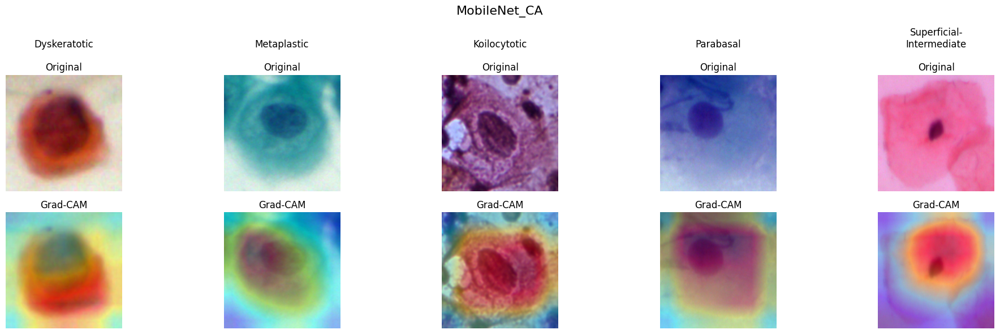


Generating Grad-CAM for: DenseNet_GAP


  DenseNet_GAP: feature map 7x7 | predictions ['Dysk', 'Meta', 'Koil', 'Para', 'Supe']


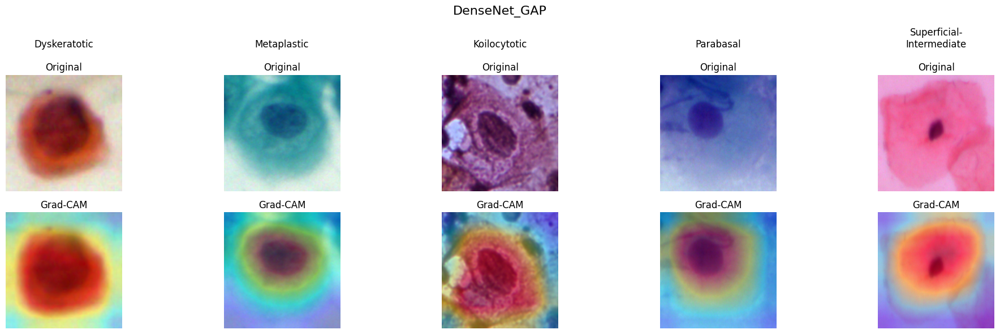


Generating Grad-CAM for: DenseNet_CA


  DenseNet_CA: feature map 7x7 | predictions ['Dysk', 'Meta', 'Koil', 'Para', 'Supe']


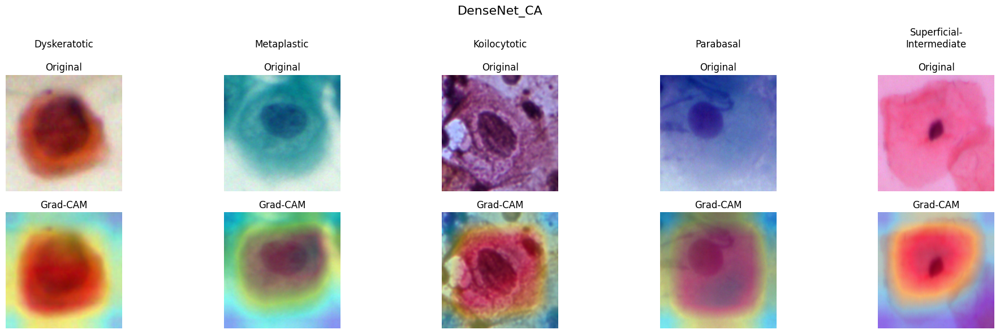


Generating Grad-CAM for: Xception_GAP


2026-11-14 07:57:02.127954: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-14 07:57:02.264574: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-14 07:57:03.041813: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-14 07:57:03.181724: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-14 07:57:03.315342: E external/local_xla/xla/stream_

  Xception_GAP: feature map 7x7 | predictions ['Dysk', 'Meta', 'Koil', 'Para', 'Supe']


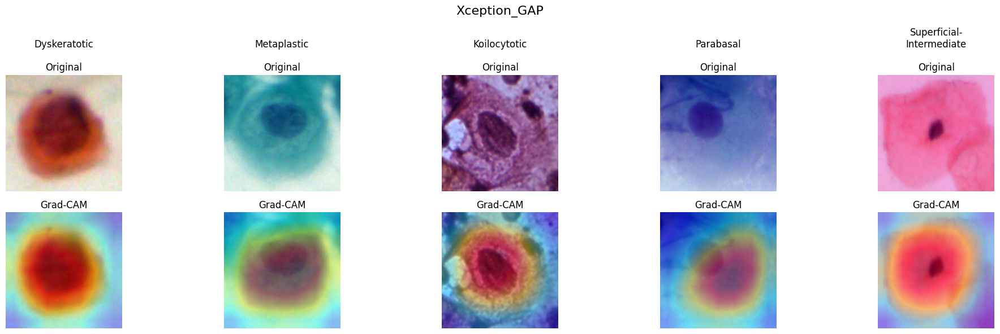


Generating Grad-CAM for: Xception_CA


  Xception_CA: feature map 7x7 | predictions ['Dysk', 'Meta', 'Koil', 'Para', 'Supe']


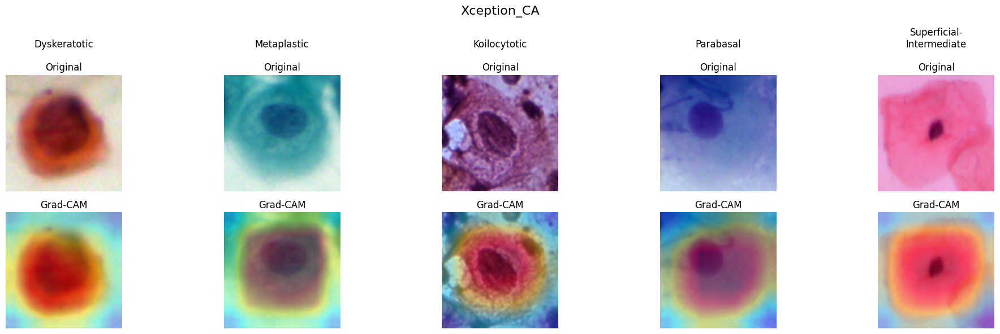


Generating Grad-CAM for: Inception_GAP


  Inception_GAP: feature map 5x5 | predictions ['Dysk', 'Meta', 'Koil', 'Para', 'Supe']


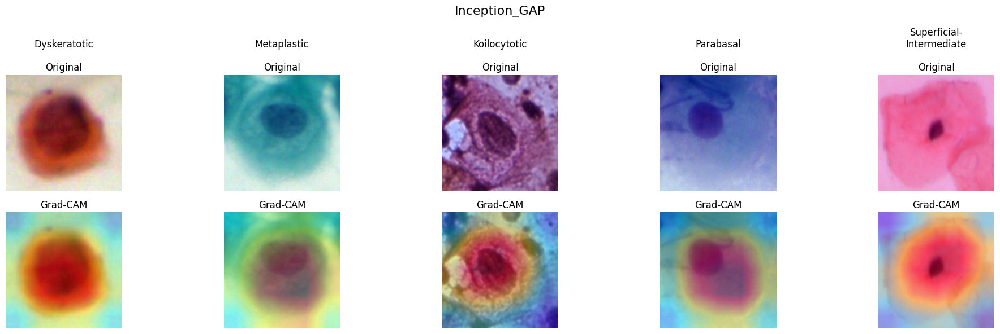


Generating Grad-CAM for: Inception_CA


  Inception_CA: feature map 5x5 | predictions ['Dysk', 'Meta', 'Koil', 'Para', 'Supe']


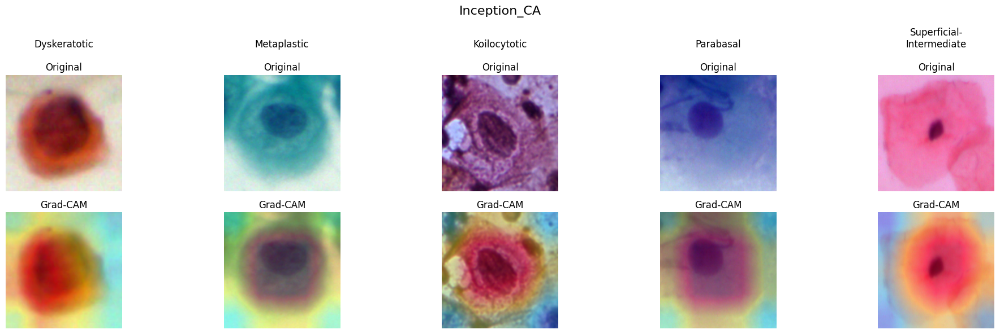

In [29]:
for backbone in versions:
    for variant in ["GAP", "CA"]:
        name = f"{backbone}_{variant}"
        print(f"\nGenerating Grad-CAM for: {name}")
        cam, preds, _ = run_gradcam(name)
        show_gradcam(name, cam)

stacked ensemble


Generating Grad-CAM for ensemble: VGG16_CA + Inception_CA
ensemble predictions: [0, 1, 2, 3, 4] | true: [0, 1, 2, 3, 4]
member weights per image: {'VGG16_CA': [0.57, 0.49, 0.46, 0.55, 0.44], 'Inception_CA': [0.43, 0.51, 0.54, 0.45, 0.56]}


  VGG16_CA: feature map 7x7 | predictions ['Dysk', 'Meta', 'Koil', 'Para', 'Supe']


  Inception_CA: feature map 5x5 | predictions ['Dysk', 'Meta', 'Koil', 'Para', 'Supe']


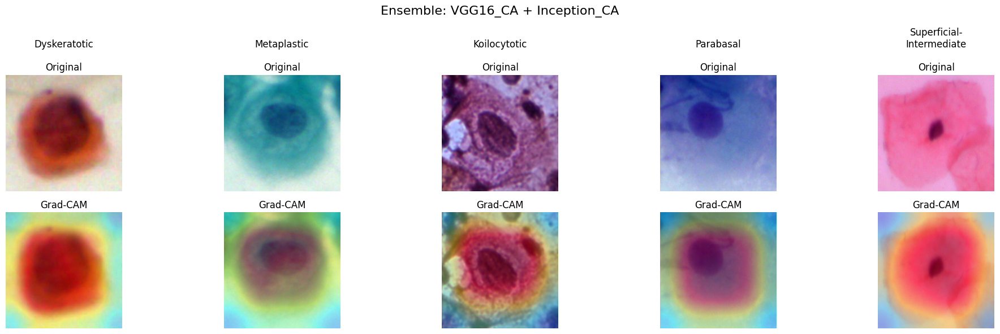


Generating Grad-CAM for ensemble: VGG16_CA + ResNet50_CA
ensemble predictions: [0, 1, 2, 3, 4] | true: [0, 1, 2, 3, 4]
member weights per image: {'VGG16_CA': [0.61, 0.54, 0.54, 0.52, 0.52], 'ResNet50_CA': [0.39, 0.46, 0.46, 0.48, 0.48]}


  ResNet50_CA: feature map 7x7 | predictions ['Dysk', 'Meta', 'Koil', 'Para', 'Supe']


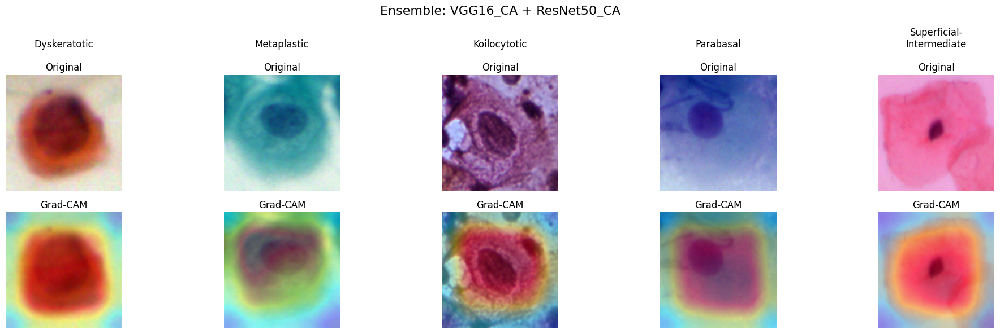


Generating Grad-CAM for ensemble: VGG16_CA + VGG19_CA + ResNet50_CA + Inception_CA
ensemble predictions: [0, 1, 2, 3, 4] | true: [0, 1, 2, 3, 4]
member weights per image: {'VGG16_CA': [0.32, 0.25, 0.2, 0.29, 0.22], 'VGG19_CA': [0.25, 0.28, 0.34, 0.26, 0.23], 'ResNet50_CA': [0.19, 0.22, 0.2, 0.23, 0.21], 'Inception_CA': [0.25, 0.25, 0.25, 0.22, 0.34]}


  VGG19_CA: feature map 7x7 | predictions ['Dysk', 'Meta', 'Koil', 'Para', 'Supe']


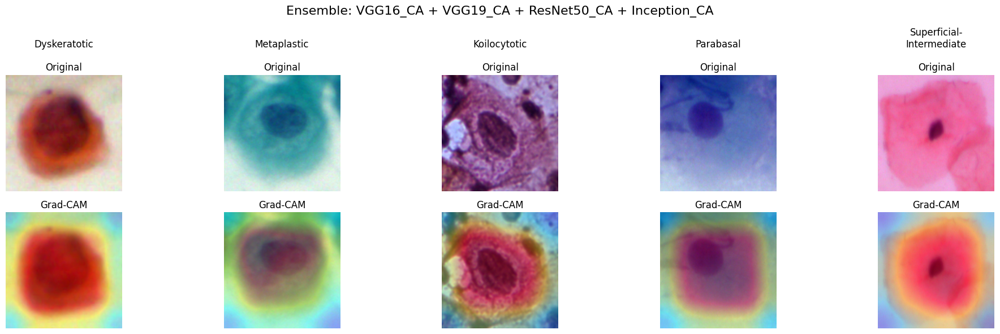

In [30]:
def gradcam_ensemble(members):
    n, K_ = len(gradcam_idx), num_classes
    lr = LogisticRegression(max_iter=2000, random_state=42)
    lr.fit(np.hstack([val_predictions[m] for m in members]), y_val_classes)
    assert np.array_equal(lr.classes_, np.arange(K_))
    member_probs = [test_predictions[m][gradcam_idx] for m in members]
    ens_pred = lr.predict(np.hstack(member_probs))

    contrib = np.array([[lr.coef_[ens_pred[i], j * K_:(j + 1) * K_] @ member_probs[j][i]
                         for j in range(len(members))] for i in range(n)])
    w = np.clip(contrib, 0, None)
    w[w.sum(1) == 0] = 1.0
    w = w / w.sum(1, keepdims=True)
    print("ensemble predictions:", ens_pred.tolist(), "| true:", y_test_classes[gradcam_idx].tolist())
    print("member weights per image:", {m: np.round(w[:, j], 2).tolist() for j, m in enumerate(members)})

    h, wd = X_test.shape[1:3]
    cams = [run_gradcam(m, targets=ens_pred)[0] for m in members]
    up = lambda m: cv2.resize(m.astype(np.float32), (wd, h), interpolation=cv2.INTER_CUBIC)
    fused = []
    for i in range(n):
        f = sum(w[i, j] * np.clip(up(cams[j][i]), 0, 1) for j in range(len(members)))
        fused.append(f / (f.max() + 1e-8))
    show_gradcam("Ensemble: " + " + ".join(members), fused)


ensemble_list = [["VGG16_CA", "Inception_CA"], ["VGG16_CA", "ResNet50_CA"]]
if "best_name" in globals() and best_name.split(" + ") not in ensemble_list:
    ensemble_list.append(best_name.split(" + "))        

for members in ensemble_list:
    print("\nGenerating Grad-CAM for ensemble:", " + ".join(members))
    gradcam_ensemble(members)